In [12]:
import pandas as pd
import numpy as np
import os
import math
import seaborn as sns
import matplotlib.pyplot as plt
import librosa
import copy
import librosa.display
from IPython.display import Audio
import csv
import warnings
warnings.filterwarnings('ignore')
import pywt
import librosa
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import torchvision.models as models
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

In [29]:

class Resnet18_LSTM_Model(nn.Module):
    def __init__(self, num_classes):
        super(Resnet18_LSTM_Model, self).__init__()
        # CNN feature extractor
        self.cnn = models.resnet18(pretrained=True)
        self.cnn.fc = nn.Identity()
        self.cnn.conv1 = nn.Conv2d(1, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
        
        # LSTM sequence model
        self.lstm = nn.LSTM(input_size=512, hidden_size=128, num_layers=1, batch_first=True)
        
        # Classification head
        self.fc = nn.Linear(128, num_classes)
        
    def forward(self, x):
        # Add a channel dimension to the input data
        x = x.unsqueeze(1)
        
        
        # CNN feature extraction
        features = self.cnn(x)

        # Reshape features for LSTM input (batch_size, sequence_length, num_features)
        features = features.unsqueeze(1)

        # LSTM sequence modeling
        lstm_output, _ = self.lstm(features)

        # Classification
        output = self.fc(lstm_output[:, -1, :])

        return output


In [3]:
# Define your custom dataset
class SpeechDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


In [4]:
# Function to calculate evaluation metrics
def calculate_metrics(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    
    # Convert from one-hot encoding to class labels if needed
    if len(y_true.shape) > 1:
        y_true = np.argmax(y_true, axis=1)
    if len(y_pred.shape) > 1:
        y_pred = np.argmax(y_pred, axis=1)
    
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')
    return accuracy, precision, recall, f1


# Validation function
def validate(model, val_loader, criterion, device):
    model.eval()
    val_loss = 0.0
    y_true = []
    y_pred = []
    
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs = inputs.to(device)
            labels = torch.argmax(labels, axis=1).to(device)  # Convert one-hot to class labels
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs, 1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())

    val_loss /= len(val_loader.dataset)
    accuracy, precision, recall, f1 = calculate_metrics(y_true, y_pred)
    
    return val_loss, accuracy, precision, recall, f1


In [5]:
def plot_graphs(epochs_path,
                num_epochs,
                train_losses,
                val_losses,
                train_accuracies,
                val_accuracies,
                train_precisions,
                val_precisions,
                train_recalls,
                val_recalls,
                train_f1s,
                val_f1s):
    
    
    # Plotting the metrics
    epochs = list(range(num_epochs))

    plt.figure(figsize=(10, 6))
    
    plt.plot(epochs, train_losses, label='Training Loss')
    plt.plot(epochs, val_losses, label='Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title('Training and Validation Loss')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'loss_plot.png'))
    plt.show()
    plt.close()

    plt.figure(figsize=(10, 6))
    
    plt.plot(epochs, train_accuracies, label='Training Accuracy')
    plt.plot(epochs, val_accuracies, label='Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'accuracy_plot.png'))
    plt.show()
    plt.close()


    plt.figure(figsize=(10, 6))

    plt.plot(epochs, train_precisions, label='Training Precision')
    plt.plot(epochs, val_precisions, label='Validation Precision')
    plt.xlabel('Epochs')
    plt.ylabel('Precision')
    plt.title('Training and Validation Precision')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'precision_plot.png'))
    plt.show()
    plt.close()
    
    plt.figure(figsize=(10, 6))

    plt.plot(epochs, train_recalls, label='Training Recall')
    plt.plot(epochs, val_recalls, label='Validation Recall')
    plt.xlabel('Epochs')
    plt.ylabel('Recall')
    plt.title('Training and Validation Recall')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'recall_plot.png'))
    plt.show()
    plt.close()

    plt.figure(figsize=(10, 6))
    
    plt.plot(epochs, train_f1s, label='Training F1-score')
    plt.plot(epochs, val_f1s, label='Validation F1-score')
    plt.xlabel('Epochs')
    plt.ylabel('F1-score')
    plt.title('Training and Validation F1-score')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'f1Score_plot.png'))
    plt.show()
    plt.close()

    return "Model Training and Evaluation Successfully completed"

In [6]:
def generate_confusion_matrix(model, test_loader, device):
    model.eval()
    y_true = []
    y_pred = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            labels = torch.argmax(labels, axis=1).to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())
            
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')        
    print(f"\nAccuracy : {accuracy}\nPrecision : {precision}\nRecall : {recall}\nF1-Score : {f1}")

    conf_matrix = confusion_matrix(y_true, y_pred)
    return conf_matrix, y_true, y_pred

def plot_confusion_matrices(conf_matrix, normalized_conf_matrix, class_labels, epochs_path):
    plt.figure(figsize=(10, 6))
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', annot_kws={"fontsize": 12})  
    plt.xlabel('Predicted labels')
    plt.ylabel('True labels')
    plt.title('Confusion Matrix')
    plt.xticks(ticks=np.arange(len(class_labels)), labels=class_labels)
    plt.yticks(ticks=np.arange(len(class_labels)), labels=class_labels)
    plt.savefig(os.path.join(epochs_path, 'Confusion Matrix.png'))
    plt.show()
    
    plt.figure(figsize=(10, 6))
    sns.heatmap(normalized_conf_matrix, annot=True, cmap='Blues', annot_kws={"fontsize": 12})
    plt.xlabel('Predicted labels')
    plt.ylabel('True labels')
    plt.title('Normalized Confusion Matrix')
    plt.xticks(ticks=np.arange(len(class_labels)), labels=class_labels)
    plt.yticks(ticks=np.arange(len(class_labels)), labels=class_labels)
    plt.savefig(os.path.join(epochs_path, 'Normalized Confusion Matrix.png'))
    plt.show()


In [16]:
def train_model():
    
    global mfcc,model
    
    dataset=input("Enter dataset name:\ntess, savee, crema, ravdess\n ")
    mfcc = int(input("Enter N_MFCC:  "))
    
    if dataset=="tess":
        csv_file=r"C:\Users\Tharunraj_S\Desktop\Major project\Dataset\tess_dataset.csv"
    
    elif dataset=="savee":
        csv_file=r"C:\Users\Tharunraj_S\Desktop\Major project\Dataset\savee_dataset.csv"
    
    elif dataset=="crema":
        csv_file=r"C:\Users\Tharunraj_S\Desktop\Major project\Dataset\crema_dataset.csv"
    
    elif dataset=="ravdess":
        csv_file=r"C:\Users\Tharunraj_S\Desktop\Major project\Dataset\ravdess_dataset.csv"
    
    
    df = pd.read_csv(csv_file)
    X_mfcc = df['File_Path'].apply(lambda x: extract_mfcc(x,mfcc))
    
    X = [x for x in X_mfcc]
    X = np.array(X)
    ## input split
    X = X.reshape(-1, 1, mfcc)
    
    class_labels = df['Emotion_Label'].unique().tolist()
    
    from sklearn.preprocessing import OneHotEncoder
    enc = OneHotEncoder()
    y = enc.fit_transform(df[['Emotion_Label']])
    y = y.toarray()
    
    train_loader, val_loader = Loader(X, y) 
      
    # Determine input size based on wavelet level
    input_size = 1
    hidden_size = 256
    num_layers = 1
        
    # Initialize model
    model = Resnet18_LSTM_Model(num_classes=num_classes)
    print("Training with N_MFCC:", mfcc)
    print(f'Input size : {input_size}\n' 
          f'Hidden Size : {hidden_size}\n' 
          f'Model Name: {model.__class__.__name__}\n' 
          f'\nX Shape : {X.shape}'
          f'\nY Shape : {y.shape}\n')
    
    model_path=model.__class__.__name__
    if not os.path.exists( model_path):
        os.makedirs( model_path)
        
    # Loss and optimizer
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # Reset model parameters
    model.apply(reset_parameters)
    
    # Reset optimizer state
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # Initialize variables to store best validation metrics and corresponding model state
    best_val_loss = float('inf')
    best_model_state = None
    
    # Training loop
    
    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []
    train_precisions = []
    val_precisions = []
    train_recalls = []
    val_recalls = []
    train_f1s = []
    val_f1s = []
    
    
    num_epochs =int(input("Enter no. of epochs "))
    
    dataset_path = dataset
    dataset_dir = os.path.join(model_path,dataset_path)
    if not os.path.exists(dataset_dir):
        os.makedirs(dataset_dir)
    
    mfcc_level_path = "level "+str(mfcc)+" wavelet"
    mfcc_level_dir = os.path.join(dataset_dir,mfcc_level_path)
    if not os.path.exists(mfcc_level_dir):
        os.makedirs(mfcc_level_dir)
    
    # Create a directory with the name as the number of epochs
    epochs_dir = str(num_epochs)+" Epochs"
    epochs_path = os.path.join(mfcc_level_dir,epochs_dir)
    if not os.path.exists(epochs_path):
        os.makedirs(epochs_path)
        
    with open(os.path.join(epochs_path,'metrics.csv'), mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(['Epoch', 'Training Loss', 'Training Accuracy','Training Precision', 'Training Recall', 'Training F1-Score'
                         , 'Validation Loss', 'Validation Accuracy','Validatio Precision', 'Validatio Recall', 'Validatio F1-Score'])

        for epoch in range(num_epochs):
            model.train()
            running_loss = 0.0

            for inputs, labels in train_loader:
                inputs = inputs.to(device)
                labels = labels.to(device)
                optimizer.zero_grad()
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                loss.backward()
                optimizer.step()
                running_loss += loss.item() * inputs.size(0)

            # Calculate training loss
            train_loss = running_loss / len(train_loader.dataset)
            train_losses.append(train_loss)

            # Calculate training metrics
            y_true_train = []
            y_pred_train = []
            with torch.no_grad():
                for inputs, labels in train_loader:
                    inputs = inputs.to(device)
                    labels = labels.to(device)
                    outputs = model(inputs)
                    _, predicted = torch.max(outputs, 1)
                    y_true_train.extend(labels.cpu().numpy())
                    y_pred_train.extend(predicted.cpu().numpy())

            train_accuracy, train_precision, train_recall, train_f1 = calculate_metrics(y_true_train, y_pred_train)
            train_accuracies.append(train_accuracy)
            train_precisions.append(train_precision)
            train_recalls.append(train_recall)
            train_f1s.append(train_f1)

            # Validate the model
            val_loss, val_accuracy, val_precision, val_recall, val_f1 = validate(model, val_loader, criterion, device)
            val_losses.append(val_loss)
            val_accuracies.append(val_accuracy)
            val_precisions.append(val_precision)
            val_recalls.append(val_recall)
            val_f1s.append(val_f1)

            # Write metrics to CSV
            writer.writerow([epoch+1, train_loss, train_accuracy, train_precision, train_recall, train_f1,
                             val_loss, val_accuracy, val_precision, val_recall, val_f1])


            print(f'Epoch [{epoch+1}/{num_epochs}],\n'
                  f'Training Loss: {train_loss:.4f}, Training Accuracy: {train_accuracy:.4f}, '
                  f'Training Precision:{train_precision:.4f},Training Recall:{train_recall:.4f},Training F1-Score:{train_f1:.4f}\n'
                  f'Validation Loss: {val_loss:.4f}, Validation Accuracy: {val_accuracy:.4f}, '
                  f'Validation Precision:{val_precision:.4f},Validation Recall:{val_recall:.4f},Validation F1-Score:{val_f1:.4f}'
                  )
            # Save the model
            torch.save(model.state_dict(), os.path.join(epochs_path, 'LSTM_model_(last).pth'))

            # Save the model if it has the best validation loss so far
            if val_loss < best_val_loss:
                best_val_loss = val_loss
                best_model_state = model.state_dict()
                torch.save(model.state_dict(), os.path.join(epochs_path, 'LSTM_model_(best).pth'))

    # Load the best model state
    model.load_state_dict(best_model_state)
    conf_matrix, _, _ = generate_confusion_matrix(model, val_loader, device)
    normalized_conf_matrix = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]
    plot_confusion_matrices(conf_matrix, normalized_conf_matrix, class_labels, epochs_path)
     
    return plot_graphs(epochs_path,num_epochs,train_losses,val_losses,train_accuracies,val_accuracies,train_precisions,val_precisions,train_recalls,val_recalls,train_f1s,val_f1s)


def reset_parameters(layer):
    if isinstance(layer, nn.Conv1d) or isinstance(layer, nn.Linear):
        nn.init.xavier_uniform_(layer.weight)
        nn.init.zeros_(layer.bias)

In [20]:
def Loader(X,y):
    
    global num_classes

    
    num_classes = y.shape[1]
    print(f"No. of classes {num_classes}")
    
    # Train-test split
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Convert to PyTorch tensors
    X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
    X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
    y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
    y_test_tensor = torch.tensor(y_test, dtype=torch.float32)

    train_dataset = SpeechDataset(X_train_tensor, y_train_tensor)
    val_dataset = SpeechDataset(X_test_tensor, y_test_tensor)


    train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
    val_loader= DataLoader(val_dataset, batch_size=64, shuffle=True)

    return train_loader, val_loader

In [9]:
def extract_mfcc(filename, mfcc):
    
    y, sr = librosa.load(filename, duration=3, offset=0.5)
    mfcc = np.mean(librosa.feature.mfcc(y=y, sr=sr, n_mfcc=mfcc).T, axis=0)
    
    return mfcc

In [10]:
# Define device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


# SAVEE

# N_MFCC 16


# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 savee
Enter N_MFCC:  16
No. of classes 6
Training with N_MFCC: 16
Input size : 1
Hidden Size : 256
Model Name: Resnet18_LSTM_Model

X Shape : (480, 1, 16)
Y Shape : (480, 6)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.7038, Training Accuracy: 0.4089, Training Precision:0.4310,Training Recall:0.4089,Training F1-Score:0.3553
Validation Loss: 1.7214, Validation Accuracy: 0.3750, Validation Precision:0.3360,Validation Recall:0.3750,Validation F1-Score:0.3369
Epoch [2/500],
Training Loss: 1.4975, Training Accuracy: 0.4688, Training Precision:0.4103,Training Recall:0.4688,Training F1-Score:0.4187
Validation Loss: 1.5373, Validation Accuracy: 0.4167, Validation Precision:0.3857,Validation Recall:0.4167,Validation F1-Score:0.3548
Epoch [3/500],
Training Loss: 1.3295, Training Accuracy: 0.5130, Training Precision:0.5329,Training Recall:0.5130,Training F1-Score:0.4787
Validation Loss: 1.2640, Validation Accuracy: 0.4896, Validation Pr

Epoch [31/500],
Training Loss: 0.6143, Training Accuracy: 0.7734, Training Precision:0.7790,Training Recall:0.7734,Training F1-Score:0.7715
Validation Loss: 1.0031, Validation Accuracy: 0.6562, Validation Precision:0.6586,Validation Recall:0.6562,Validation F1-Score:0.6549
Epoch [32/500],
Training Loss: 0.5978, Training Accuracy: 0.7474, Training Precision:0.7487,Training Recall:0.7474,Training F1-Score:0.7414
Validation Loss: 1.0665, Validation Accuracy: 0.5833, Validation Precision:0.6005,Validation Recall:0.5833,Validation F1-Score:0.5866
Epoch [33/500],
Training Loss: 0.7002, Training Accuracy: 0.7370, Training Precision:0.7425,Training Recall:0.7370,Training F1-Score:0.7343
Validation Loss: 1.2597, Validation Accuracy: 0.5938, Validation Precision:0.6249,Validation Recall:0.5938,Validation F1-Score:0.5999
Epoch [34/500],
Training Loss: 0.7289, Training Accuracy: 0.7318, Training Precision:0.7393,Training Recall:0.7318,Training F1-Score:0.7261
Validation Loss: 1.1272, Validation Ac

Epoch [61/500],
Training Loss: 0.3822, Training Accuracy: 0.9036, Training Precision:0.9075,Training Recall:0.9036,Training F1-Score:0.9028
Validation Loss: 1.1242, Validation Accuracy: 0.6458, Validation Precision:0.6735,Validation Recall:0.6458,Validation F1-Score:0.6415
Epoch [62/500],
Training Loss: 0.4102, Training Accuracy: 0.8229, Training Precision:0.8255,Training Recall:0.8229,Training F1-Score:0.8218
Validation Loss: 1.3859, Validation Accuracy: 0.5625, Validation Precision:0.6062,Validation Recall:0.5625,Validation F1-Score:0.5646
Epoch [63/500],
Training Loss: 0.5146, Training Accuracy: 0.8568, Training Precision:0.8571,Training Recall:0.8568,Training F1-Score:0.8566
Validation Loss: 1.6748, Validation Accuracy: 0.5521, Validation Precision:0.6457,Validation Recall:0.5521,Validation F1-Score:0.5732
Epoch [64/500],
Training Loss: 0.5338, Training Accuracy: 0.8385, Training Precision:0.8438,Training Recall:0.8385,Training F1-Score:0.8356
Validation Loss: 1.3395, Validation Ac

Epoch [91/500],
Training Loss: 0.3179, Training Accuracy: 0.8984, Training Precision:0.9007,Training Recall:0.8984,Training F1-Score:0.8978
Validation Loss: 1.5997, Validation Accuracy: 0.5729, Validation Precision:0.6621,Validation Recall:0.5729,Validation F1-Score:0.5846
Epoch [92/500],
Training Loss: 0.2895, Training Accuracy: 0.9089, Training Precision:0.9107,Training Recall:0.9089,Training F1-Score:0.9088
Validation Loss: 1.5382, Validation Accuracy: 0.5833, Validation Precision:0.6472,Validation Recall:0.5833,Validation F1-Score:0.6024
Epoch [93/500],
Training Loss: 0.2667, Training Accuracy: 0.9036, Training Precision:0.9040,Training Recall:0.9036,Training F1-Score:0.9031
Validation Loss: 2.0486, Validation Accuracy: 0.4896, Validation Precision:0.5758,Validation Recall:0.4896,Validation F1-Score:0.5134
Epoch [94/500],
Training Loss: 0.3197, Training Accuracy: 0.8620, Training Precision:0.8625,Training Recall:0.8620,Training F1-Score:0.8619
Validation Loss: 1.3375, Validation Ac

Epoch [121/500],
Training Loss: 0.3407, Training Accuracy: 0.9167, Training Precision:0.9174,Training Recall:0.9167,Training F1-Score:0.9161
Validation Loss: 1.5534, Validation Accuracy: 0.5625, Validation Precision:0.6481,Validation Recall:0.5625,Validation F1-Score:0.5791
Epoch [122/500],
Training Loss: 0.3650, Training Accuracy: 0.9036, Training Precision:0.9047,Training Recall:0.9036,Training F1-Score:0.9033
Validation Loss: 1.4554, Validation Accuracy: 0.5729, Validation Precision:0.6186,Validation Recall:0.5729,Validation F1-Score:0.5872
Epoch [123/500],
Training Loss: 0.3164, Training Accuracy: 0.8802, Training Precision:0.8806,Training Recall:0.8802,Training F1-Score:0.8799
Validation Loss: 1.7290, Validation Accuracy: 0.5729, Validation Precision:0.6391,Validation Recall:0.5729,Validation F1-Score:0.5827
Epoch [124/500],
Training Loss: 0.3455, Training Accuracy: 0.9323, Training Precision:0.9353,Training Recall:0.9323,Training F1-Score:0.9328
Validation Loss: 1.4369, Validatio

...

Epoch [361/500],
Training Loss: 0.0155, Training Accuracy: 0.9844, Training Precision:0.9844,Training Recall:0.9844,Training F1-Score:0.9844
Validation Loss: 1.7181, Validation Accuracy: 0.6562, Validation Precision:0.6820,Validation Recall:0.6562,Validation F1-Score:0.6584
Epoch [362/500],
Training Loss: 0.0249, Training Accuracy: 0.9922, Training Precision:0.9922,Training Recall:0.9922,Training F1-Score:0.9922
Validation Loss: 1.9470, Validation Accuracy: 0.6354, Validation Precision:0.6999,Validation Recall:0.6354,Validation F1-Score:0.6469
Epoch [363/500],
Training Loss: 0.0377, Training Accuracy: 0.9844, Training Precision:0.9846,Training Recall:0.9844,Training F1-Score:0.9843
Validation Loss: 1.7669, Validation Accuracy: 0.6562, Validation Precision:0.6936,Validation Recall:0.6562,Validation F1-Score:0.6617
Epoch [364/500],
Training Loss: 0.0547, Training Accuracy: 0.9870, Training Precision:0.9872,Training Recall:0.9870,Training F1-Score:0.9870
Validation Loss: 1.4394, Validatio

Epoch [391/500],
Training Loss: 0.0309, Training Accuracy: 0.9870, Training Precision:0.9872,Training Recall:0.9870,Training F1-Score:0.9869
Validation Loss: 1.6134, Validation Accuracy: 0.7083, Validation Precision:0.7178,Validation Recall:0.7083,Validation F1-Score:0.7027
Epoch [392/500],
Training Loss: 0.0432, Training Accuracy: 0.9818, Training Precision:0.9820,Training Recall:0.9818,Training F1-Score:0.9817
Validation Loss: 1.5906, Validation Accuracy: 0.7083, Validation Precision:0.7085,Validation Recall:0.7083,Validation F1-Score:0.6987
Epoch [393/500],
Training Loss: 0.0486, Training Accuracy: 0.9792, Training Precision:0.9794,Training Recall:0.9792,Training F1-Score:0.9791
Validation Loss: 1.6441, Validation Accuracy: 0.6667, Validation Precision:0.6763,Validation Recall:0.6667,Validation F1-Score:0.6637
Epoch [394/500],
Training Loss: 0.0845, Training Accuracy: 0.9870, Training Precision:0.9872,Training Recall:0.9870,Training F1-Score:0.9870
Validation Loss: 1.7849, Validatio

Epoch [421/500],
Training Loss: 0.1017, Training Accuracy: 0.9635, Training Precision:0.9650,Training Recall:0.9635,Training F1-Score:0.9635
Validation Loss: 1.8714, Validation Accuracy: 0.6146, Validation Precision:0.6819,Validation Recall:0.6146,Validation F1-Score:0.6227
Epoch [422/500],
Training Loss: 0.1618, Training Accuracy: 0.9661, Training Precision:0.9680,Training Recall:0.9661,Training F1-Score:0.9660
Validation Loss: 1.5386, Validation Accuracy: 0.6667, Validation Precision:0.6910,Validation Recall:0.6667,Validation F1-Score:0.6693
Epoch [423/500],
Training Loss: 0.1287, Training Accuracy: 0.9714, Training Precision:0.9720,Training Recall:0.9714,Training F1-Score:0.9714
Validation Loss: 1.4947, Validation Accuracy: 0.7083, Validation Precision:0.7343,Validation Recall:0.7083,Validation F1-Score:0.7118
Epoch [424/500],
Training Loss: 0.0581, Training Accuracy: 0.9792, Training Precision:0.9798,Training Recall:0.9792,Training F1-Score:0.9792
Validation Loss: 1.5342, Validatio

Epoch [451/500],
Training Loss: 0.0420, Training Accuracy: 0.9818, Training Precision:0.9821,Training Recall:0.9818,Training F1-Score:0.9818
Validation Loss: 1.6449, Validation Accuracy: 0.6771, Validation Precision:0.7061,Validation Recall:0.6771,Validation F1-Score:0.6822
Epoch [452/500],
Training Loss: 0.0542, Training Accuracy: 0.9818, Training Precision:0.9820,Training Recall:0.9818,Training F1-Score:0.9818
Validation Loss: 1.5394, Validation Accuracy: 0.6458, Validation Precision:0.6701,Validation Recall:0.6458,Validation F1-Score:0.6496
Epoch [453/500],
Training Loss: 0.0381, Training Accuracy: 0.9922, Training Precision:0.9923,Training Recall:0.9922,Training F1-Score:0.9922
Validation Loss: 1.6084, Validation Accuracy: 0.6562, Validation Precision:0.6853,Validation Recall:0.6562,Validation F1-Score:0.6565
Epoch [454/500],
Training Loss: 0.0589, Training Accuracy: 0.9818, Training Precision:0.9820,Training Recall:0.9818,Training F1-Score:0.9818
Validation Loss: 1.6387, Validatio

Epoch [481/500],
Training Loss: 0.0512, Training Accuracy: 0.9870, Training Precision:0.9873,Training Recall:0.9870,Training F1-Score:0.9868
Validation Loss: 1.6914, Validation Accuracy: 0.6458, Validation Precision:0.6457,Validation Recall:0.6458,Validation F1-Score:0.6374
Epoch [482/500],
Training Loss: 0.0583, Training Accuracy: 0.9870, Training Precision:0.9871,Training Recall:0.9870,Training F1-Score:0.9870
Validation Loss: 1.5686, Validation Accuracy: 0.6458, Validation Precision:0.6760,Validation Recall:0.6458,Validation F1-Score:0.6522
Epoch [483/500],
Training Loss: 0.0500, Training Accuracy: 0.9896, Training Precision:0.9898,Training Recall:0.9896,Training F1-Score:0.9896
Validation Loss: 1.4839, Validation Accuracy: 0.6771, Validation Precision:0.6975,Validation Recall:0.6771,Validation F1-Score:0.6793
Epoch [484/500],
Training Loss: 0.0567, Training Accuracy: 0.9948, Training Precision:0.9949,Training Recall:0.9948,Training F1-Score:0.9948
Validation Loss: 1.3860, Validatio

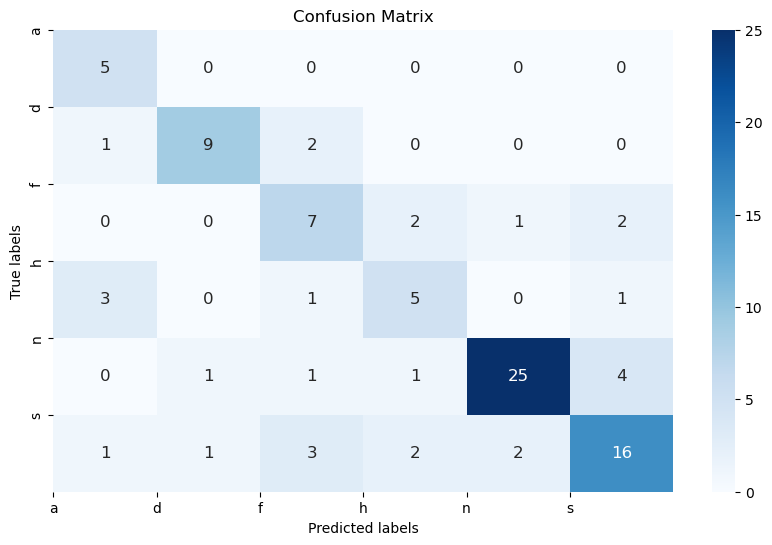

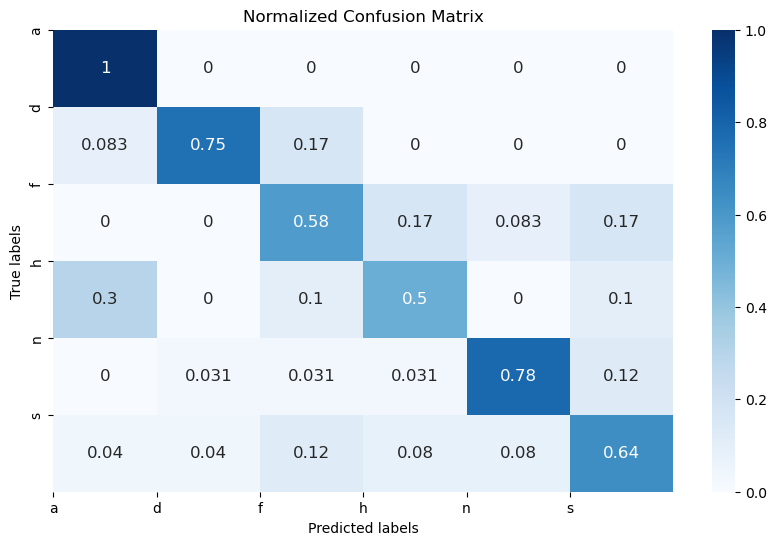

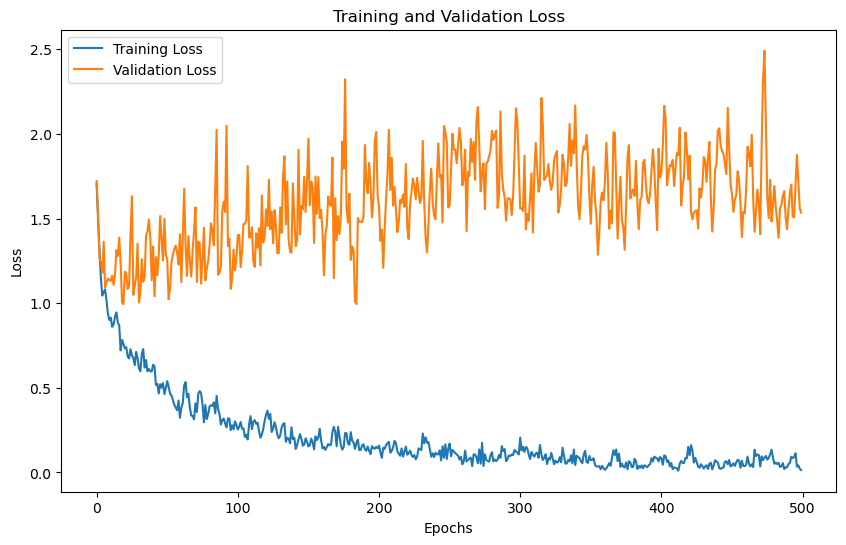

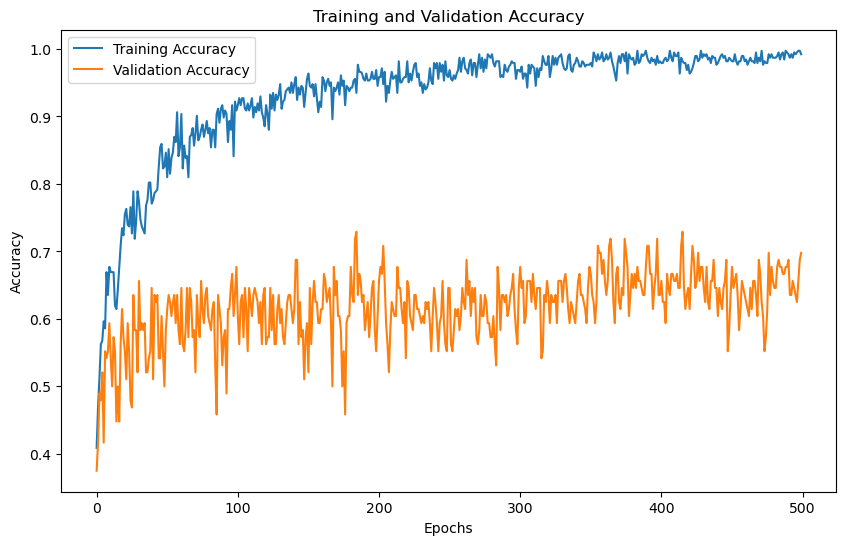

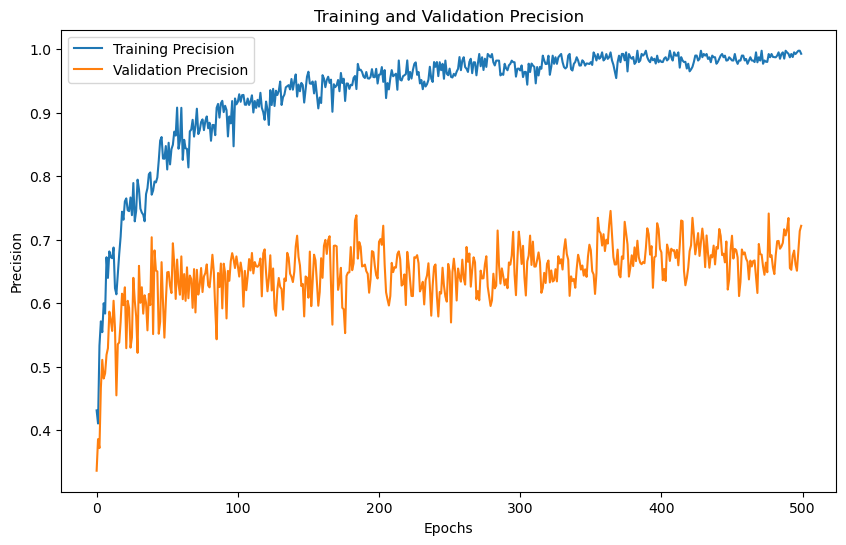

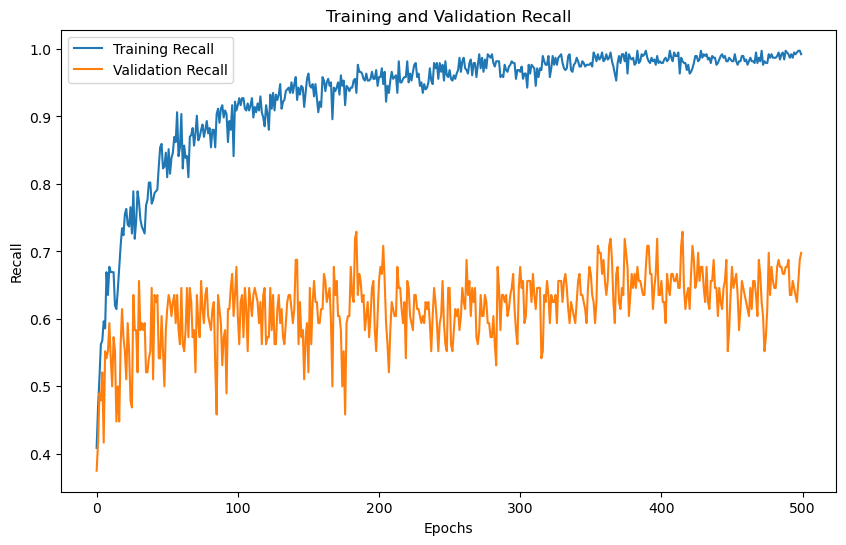

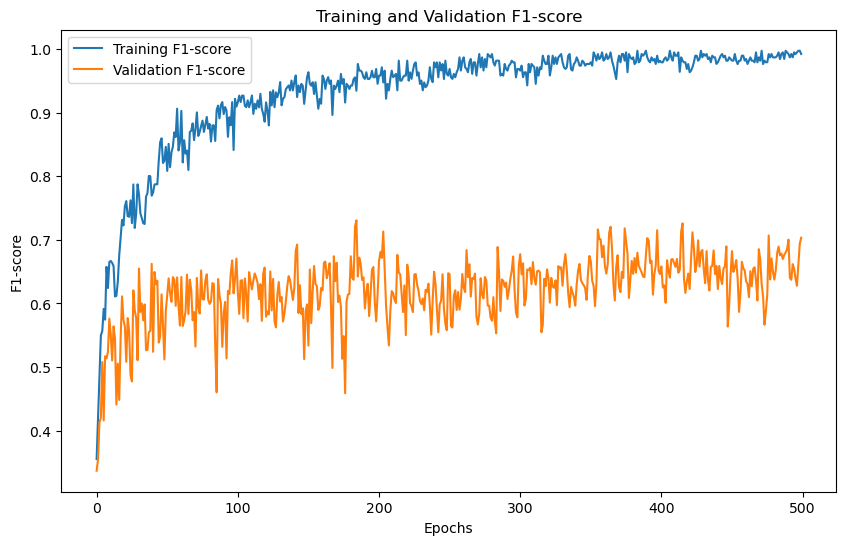

'Model Training and Evaluation Successfully completed'

In [17]:
train_model()

# N_MFCC= 24

# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 savee
Enter N_MFCC:  24
No. of classes 6
Training with N_MFCC: 24
Input size : 1
Hidden Size : 256
Model Name: Resnet18_LSTM_Model

X Shape : (480, 1, 24)
Y Shape : (480, 6)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.7659, Training Accuracy: 0.3482, Training Precision:0.3823,Training Recall:0.3482,Training F1-Score:0.2942
Validation Loss: 1.7163, Validation Accuracy: 0.2917, Validation Precision:0.0851,Validation Recall:0.2917,Validation F1-Score:0.1317
Epoch [2/500],
Training Loss: 1.5042, Training Accuracy: 0.5208, Training Precision:0.5236,Training Recall:0.5208,Training F1-Score:0.4827
Validation Loss: 1.4947, Validation Accuracy: 0.4028, Validation Precision:0.3078,Validation Recall:0.4028,Validation F1-Score:0.2973
Epoch [3/500],
Training Loss: 1.2511, Training Accuracy: 0.5893, Training Precision:0.5942,Training Recall:0.5893,Training F1-Score:0.5808
Validation Loss: 1.3481, Validation Accuracy: 0.4306, Validation Pr

Epoch [31/500],
Training Loss: 0.7711, Training Accuracy: 0.7351, Training Precision:0.7332,Training Recall:0.7351,Training F1-Score:0.7315
Validation Loss: 1.2064, Validation Accuracy: 0.5278, Validation Precision:0.5234,Validation Recall:0.5278,Validation F1-Score:0.5121
Epoch [32/500],
Training Loss: 0.7382, Training Accuracy: 0.7500, Training Precision:0.7532,Training Recall:0.7500,Training F1-Score:0.7458
Validation Loss: 1.3141, Validation Accuracy: 0.5139, Validation Precision:0.5270,Validation Recall:0.5139,Validation F1-Score:0.5062
Epoch [33/500],
Training Loss: 0.6300, Training Accuracy: 0.7887, Training Precision:0.7954,Training Recall:0.7887,Training F1-Score:0.7822
Validation Loss: 1.3646, Validation Accuracy: 0.4444, Validation Precision:0.4772,Validation Recall:0.4444,Validation F1-Score:0.4292
Epoch [34/500],
Training Loss: 0.5573, Training Accuracy: 0.8185, Training Precision:0.8185,Training Recall:0.8185,Training F1-Score:0.8163
Validation Loss: 1.5610, Validation Ac

Epoch [61/500],
Training Loss: 0.5695, Training Accuracy: 0.8274, Training Precision:0.8304,Training Recall:0.8274,Training F1-Score:0.8266
Validation Loss: 1.9673, Validation Accuracy: 0.3611, Validation Precision:0.4933,Validation Recall:0.3611,Validation F1-Score:0.3394
Epoch [62/500],
Training Loss: 0.4779, Training Accuracy: 0.8601, Training Precision:0.8612,Training Recall:0.8601,Training F1-Score:0.8582
Validation Loss: 1.6471, Validation Accuracy: 0.4028, Validation Precision:0.5160,Validation Recall:0.4028,Validation F1-Score:0.4031
Epoch [63/500],
Training Loss: 0.5325, Training Accuracy: 0.8304, Training Precision:0.8365,Training Recall:0.8304,Training F1-Score:0.8301
Validation Loss: 1.4465, Validation Accuracy: 0.5139, Validation Precision:0.5586,Validation Recall:0.5139,Validation F1-Score:0.5208
Epoch [64/500],
Training Loss: 0.4780, Training Accuracy: 0.8423, Training Precision:0.8476,Training Recall:0.8423,Training F1-Score:0.8412
Validation Loss: 1.3041, Validation Ac

Epoch [91/500],
Training Loss: 0.3356, Training Accuracy: 0.8780, Training Precision:0.8812,Training Recall:0.8780,Training F1-Score:0.8776
Validation Loss: 1.1917, Validation Accuracy: 0.5972, Validation Precision:0.6221,Validation Recall:0.5972,Validation F1-Score:0.5878
Epoch [92/500],
Training Loss: 0.3694, Training Accuracy: 0.8601, Training Precision:0.8634,Training Recall:0.8601,Training F1-Score:0.8589
Validation Loss: 1.1776, Validation Accuracy: 0.5972, Validation Precision:0.6004,Validation Recall:0.5972,Validation F1-Score:0.5920
Epoch [93/500],
Training Loss: 0.3559, Training Accuracy: 0.8571, Training Precision:0.8625,Training Recall:0.8571,Training F1-Score:0.8567
Validation Loss: 1.2136, Validation Accuracy: 0.5903, Validation Precision:0.5965,Validation Recall:0.5903,Validation F1-Score:0.5806
Epoch [94/500],
Training Loss: 0.4321, Training Accuracy: 0.9137, Training Precision:0.9213,Training Recall:0.9137,Training F1-Score:0.9127
Validation Loss: 1.2355, Validation Ac

Epoch [121/500],
Training Loss: 0.4841, Training Accuracy: 0.8571, Training Precision:0.8640,Training Recall:0.8571,Training F1-Score:0.8575
Validation Loss: 1.4021, Validation Accuracy: 0.5347, Validation Precision:0.5544,Validation Recall:0.5347,Validation F1-Score:0.5372
Epoch [122/500],
Training Loss: 0.3761, Training Accuracy: 0.8601, Training Precision:0.8611,Training Recall:0.8601,Training F1-Score:0.8584
Validation Loss: 1.3478, Validation Accuracy: 0.5486, Validation Precision:0.5623,Validation Recall:0.5486,Validation F1-Score:0.5528
Epoch [123/500],
Training Loss: 0.3530, Training Accuracy: 0.9077, Training Precision:0.9085,Training Recall:0.9077,Training F1-Score:0.9072
Validation Loss: 1.4248, Validation Accuracy: 0.5417, Validation Precision:0.5648,Validation Recall:0.5417,Validation F1-Score:0.5471
Epoch [124/500],
Training Loss: 0.2999, Training Accuracy: 0.8810, Training Precision:0.8842,Training Recall:0.8810,Training F1-Score:0.8800
Validation Loss: 1.5130, Validatio

...

Epoch [361/500],
Training Loss: 0.1716, Training Accuracy: 0.9851, Training Precision:0.9854,Training Recall:0.9851,Training F1-Score:0.9851
Validation Loss: 1.5163, Validation Accuracy: 0.5972, Validation Precision:0.6249,Validation Recall:0.5972,Validation F1-Score:0.5907
Epoch [362/500],
Training Loss: 0.0825, Training Accuracy: 0.9345, Training Precision:0.9343,Training Recall:0.9345,Training F1-Score:0.9336
Validation Loss: 1.5204, Validation Accuracy: 0.6042, Validation Precision:0.6092,Validation Recall:0.6042,Validation F1-Score:0.5842
Epoch [363/500],
Training Loss: 0.2157, Training Accuracy: 0.9494, Training Precision:0.9499,Training Recall:0.9494,Training F1-Score:0.9493
Validation Loss: 1.4655, Validation Accuracy: 0.5764, Validation Precision:0.5825,Validation Recall:0.5764,Validation F1-Score:0.5702
Epoch [364/500],
Training Loss: 0.2355, Training Accuracy: 0.9524, Training Precision:0.9548,Training Recall:0.9524,Training F1-Score:0.9528
Validation Loss: 1.6227, Validatio

Epoch [391/500],
Training Loss: 0.1047, Training Accuracy: 0.9583, Training Precision:0.9598,Training Recall:0.9583,Training F1-Score:0.9586
Validation Loss: 1.2740, Validation Accuracy: 0.6528, Validation Precision:0.6554,Validation Recall:0.6528,Validation F1-Score:0.6507
Epoch [392/500],
Training Loss: 0.1193, Training Accuracy: 0.9851, Training Precision:0.9855,Training Recall:0.9851,Training F1-Score:0.9851
Validation Loss: 1.3603, Validation Accuracy: 0.6389, Validation Precision:0.6396,Validation Recall:0.6389,Validation F1-Score:0.6370
Epoch [393/500],
Training Loss: 0.1042, Training Accuracy: 0.9554, Training Precision:0.9585,Training Recall:0.9554,Training F1-Score:0.9557
Validation Loss: 1.7275, Validation Accuracy: 0.5764, Validation Precision:0.6029,Validation Recall:0.5764,Validation F1-Score:0.5802
Epoch [394/500],
Training Loss: 0.1290, Training Accuracy: 0.9613, Training Precision:0.9628,Training Recall:0.9613,Training F1-Score:0.9615
Validation Loss: 1.5532, Validatio

Epoch [421/500],
Training Loss: 0.0949, Training Accuracy: 0.9821, Training Precision:0.9823,Training Recall:0.9821,Training F1-Score:0.9821
Validation Loss: 1.4142, Validation Accuracy: 0.6319, Validation Precision:0.6422,Validation Recall:0.6319,Validation F1-Score:0.6217
Epoch [422/500],
Training Loss: 0.0634, Training Accuracy: 0.9762, Training Precision:0.9768,Training Recall:0.9762,Training F1-Score:0.9762
Validation Loss: 1.5023, Validation Accuracy: 0.5903, Validation Precision:0.6073,Validation Recall:0.5903,Validation F1-Score:0.5806
Epoch [423/500],
Training Loss: 0.0652, Training Accuracy: 0.9762, Training Precision:0.9763,Training Recall:0.9762,Training F1-Score:0.9762
Validation Loss: 1.4923, Validation Accuracy: 0.6250, Validation Precision:0.6309,Validation Recall:0.6250,Validation F1-Score:0.6173
Epoch [424/500],
Training Loss: 0.0675, Training Accuracy: 0.9554, Training Precision:0.9575,Training Recall:0.9554,Training F1-Score:0.9556
Validation Loss: 1.7369, Validatio

Epoch [451/500],
Training Loss: 0.0881, Training Accuracy: 0.9762, Training Precision:0.9768,Training Recall:0.9762,Training F1-Score:0.9759
Validation Loss: 1.4919, Validation Accuracy: 0.6181, Validation Precision:0.6190,Validation Recall:0.6181,Validation F1-Score:0.6158
Epoch [452/500],
Training Loss: 0.0880, Training Accuracy: 0.9702, Training Precision:0.9707,Training Recall:0.9702,Training F1-Score:0.9702
Validation Loss: 1.5001, Validation Accuracy: 0.6250, Validation Precision:0.6307,Validation Recall:0.6250,Validation F1-Score:0.6262
Epoch [453/500],
Training Loss: 0.0971, Training Accuracy: 0.9821, Training Precision:0.9830,Training Recall:0.9821,Training F1-Score:0.9821
Validation Loss: 1.5816, Validation Accuracy: 0.6181, Validation Precision:0.6043,Validation Recall:0.6181,Validation F1-Score:0.5979
Epoch [454/500],
Training Loss: 0.0568, Training Accuracy: 0.9792, Training Precision:0.9800,Training Recall:0.9792,Training F1-Score:0.9789
Validation Loss: 1.5514, Validatio

Epoch [481/500],
Training Loss: 0.0936, Training Accuracy: 0.9881, Training Precision:0.9881,Training Recall:0.9881,Training F1-Score:0.9881
Validation Loss: 1.9371, Validation Accuracy: 0.5625, Validation Precision:0.5676,Validation Recall:0.5625,Validation F1-Score:0.5555
Epoch [482/500],
Training Loss: 0.1203, Training Accuracy: 0.9881, Training Precision:0.9884,Training Recall:0.9881,Training F1-Score:0.9881
Validation Loss: 1.7126, Validation Accuracy: 0.5903, Validation Precision:0.5853,Validation Recall:0.5903,Validation F1-Score:0.5854
Epoch [483/500],
Training Loss: 0.0356, Training Accuracy: 0.9881, Training Precision:0.9887,Training Recall:0.9881,Training F1-Score:0.9882
Validation Loss: 1.5413, Validation Accuracy: 0.6389, Validation Precision:0.6335,Validation Recall:0.6389,Validation F1-Score:0.6346
Epoch [484/500],
Training Loss: 0.0293, Training Accuracy: 0.9851, Training Precision:0.9854,Training Recall:0.9851,Training F1-Score:0.9851
Validation Loss: 1.4086, Validatio

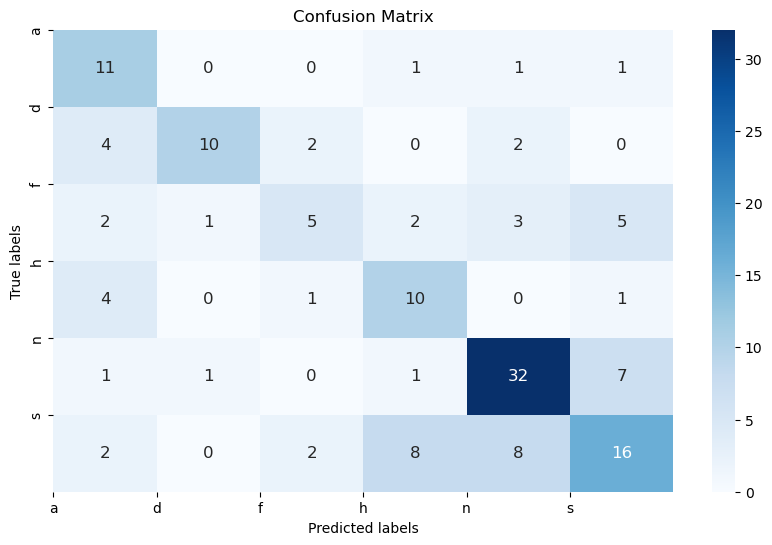

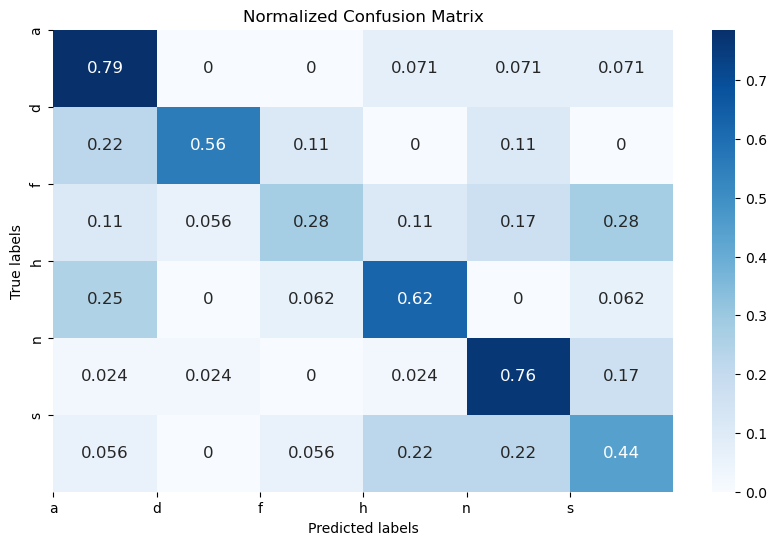

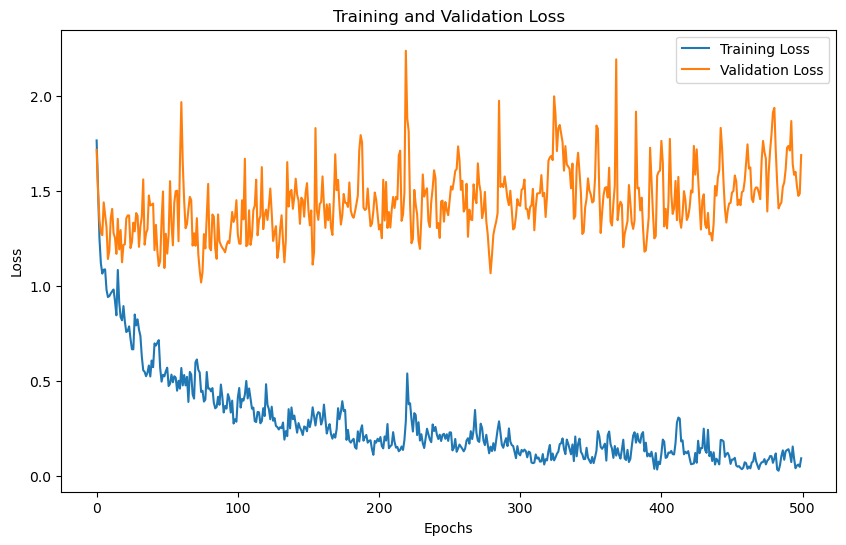

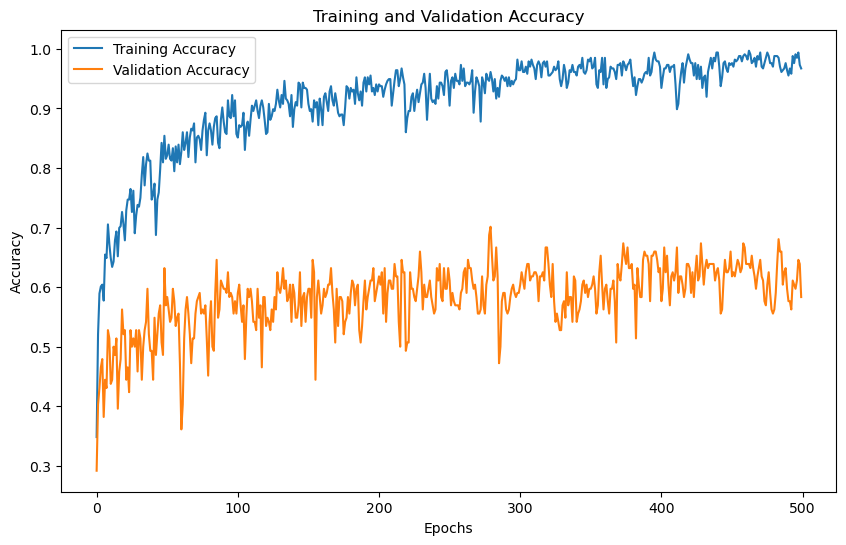

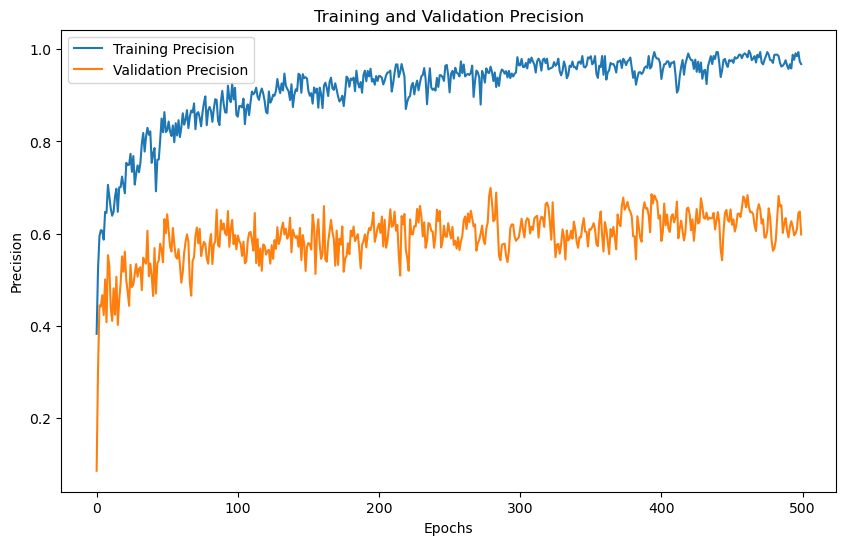

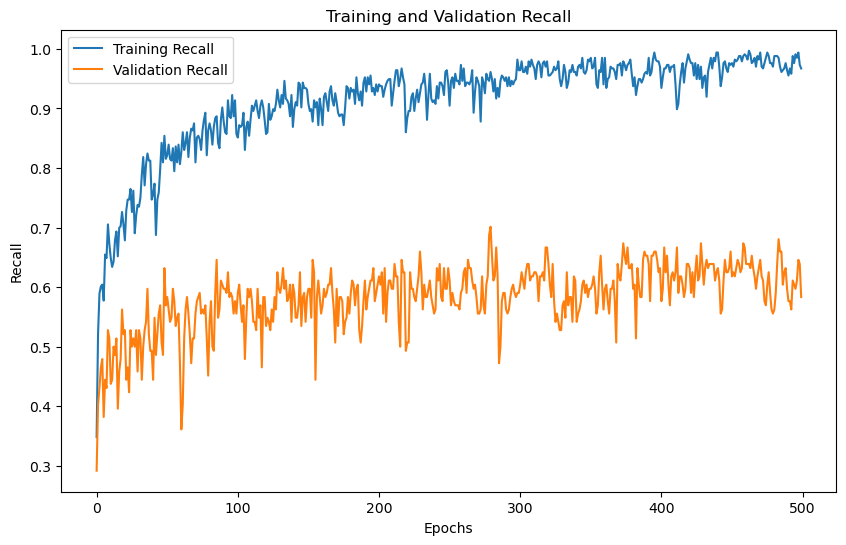

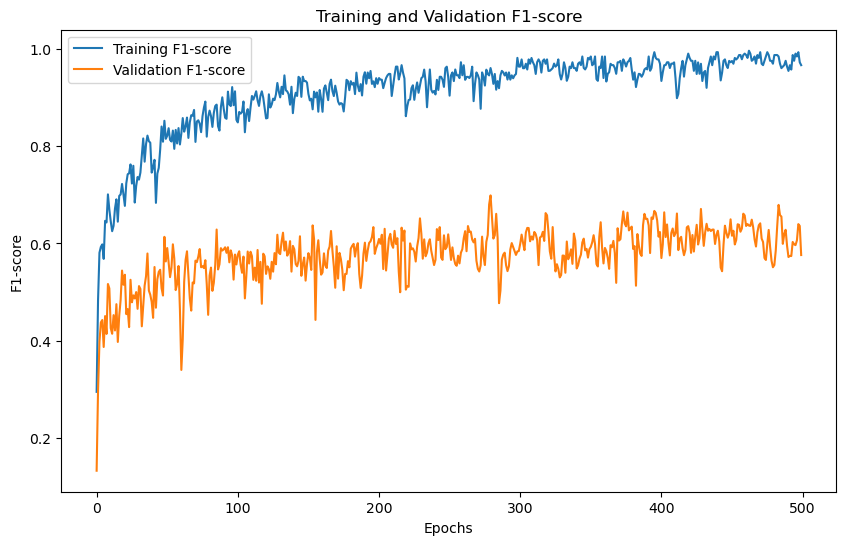

'Model Training and Evaluation Successfully completed'

In [19]:
train_model()

# N_MFCC 32

# 500 epochs

In [ ]:
train_model()

# N_MFCC 40

# 500 epochs

In [ ]:
train_model()

# RAVDESS

# N_MFCC 16

# 300 epochs

In [ ]:
train_model()

# N_MFCC 24

# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 ravdess
Enter N_MFCC:  24
No. of classes 8
Training with N_MFCC: 24
Input size : 1
Hidden Size : 256
Model Name: Resnet18_LSTM_Model

X Shape : (1440, 1, 24)
Y Shape : (1440, 8)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.9207, Training Accuracy: 0.3082, Training Precision:0.3027,Training Recall:0.3082,Training F1-Score:0.2703
Validation Loss: 1.7231, Validation Accuracy: 0.3090, Validation Precision:0.2744,Validation Recall:0.3090,Validation F1-Score:0.2704
Epoch [2/500],
Training Loss: 1.7719, Training Accuracy: 0.3585, Training Precision:0.3168,Training Recall:0.3585,Training F1-Score:0.3142
Validation Loss: 1.6306, Validation Accuracy: 0.3958, Validation Precision:0.3324,Validation Recall:0.3958,Validation F1-Score:0.3441
Epoch [3/500],
Training Loss: 1.6895, Training Accuracy: 0.4054, Training Precision:0.4459,Training Recall:0.4054,Training F1-Score:0.3706
Validation Loss: 1.5936, Validation Accuracy: 0.3681, Validatio

Epoch [31/500],
Training Loss: 0.9324, Training Accuracy: 0.6970, Training Precision:0.7016,Training Recall:0.6970,Training F1-Score:0.6968
Validation Loss: 1.4228, Validation Accuracy: 0.5000, Validation Precision:0.5082,Validation Recall:0.5000,Validation F1-Score:0.5001
Epoch [32/500],
Training Loss: 0.8842, Training Accuracy: 0.7439, Training Precision:0.7468,Training Recall:0.7439,Training F1-Score:0.7434
Validation Loss: 1.4103, Validation Accuracy: 0.5069, Validation Precision:0.5284,Validation Recall:0.5069,Validation F1-Score:0.5071
Epoch [33/500],
Training Loss: 0.8390, Training Accuracy: 0.7422, Training Precision:0.7413,Training Recall:0.7422,Training F1-Score:0.7394
Validation Loss: 1.4302, Validation Accuracy: 0.5243, Validation Precision:0.5178,Validation Recall:0.5243,Validation F1-Score:0.5162
Epoch [34/500],
Training Loss: 0.8924, Training Accuracy: 0.7300, Training Precision:0.7338,Training Recall:0.7300,Training F1-Score:0.7293
Validation Loss: 1.4388, Validation Ac

Epoch [61/500],
Training Loss: 0.4136, Training Accuracy: 0.8715, Training Precision:0.8730,Training Recall:0.8715,Training F1-Score:0.8716
Validation Loss: 1.5521, Validation Accuracy: 0.6181, Validation Precision:0.6426,Validation Recall:0.6181,Validation F1-Score:0.6184
Epoch [62/500],
Training Loss: 0.3663, Training Accuracy: 0.9010, Training Precision:0.9023,Training Recall:0.9010,Training F1-Score:0.9005
Validation Loss: 1.4370, Validation Accuracy: 0.5764, Validation Precision:0.5786,Validation Recall:0.5764,Validation F1-Score:0.5741
Epoch [63/500],
Training Loss: 0.2895, Training Accuracy: 0.9349, Training Precision:0.9353,Training Recall:0.9349,Training F1-Score:0.9349
Validation Loss: 1.4572, Validation Accuracy: 0.5868, Validation Precision:0.5902,Validation Recall:0.5868,Validation F1-Score:0.5859
Epoch [64/500],
Training Loss: 0.3265, Training Accuracy: 0.9071, Training Precision:0.9089,Training Recall:0.9071,Training F1-Score:0.9074
Validation Loss: 1.6936, Validation Ac

Epoch [91/500],
Training Loss: 0.1836, Training Accuracy: 0.9514, Training Precision:0.9532,Training Recall:0.9514,Training F1-Score:0.9515
Validation Loss: 1.6310, Validation Accuracy: 0.6007, Validation Precision:0.6128,Validation Recall:0.6007,Validation F1-Score:0.6017
Epoch [92/500],
Training Loss: 0.1542, Training Accuracy: 0.9661, Training Precision:0.9661,Training Recall:0.9661,Training F1-Score:0.9661
Validation Loss: 1.6196, Validation Accuracy: 0.5903, Validation Precision:0.5947,Validation Recall:0.5903,Validation F1-Score:0.5907
Epoch [93/500],
Training Loss: 0.0967, Training Accuracy: 0.9748, Training Precision:0.9749,Training Recall:0.9748,Training F1-Score:0.9748
Validation Loss: 1.6568, Validation Accuracy: 0.6076, Validation Precision:0.6201,Validation Recall:0.6076,Validation F1-Score:0.6079
Epoch [94/500],
Training Loss: 0.1208, Training Accuracy: 0.9635, Training Precision:0.9638,Training Recall:0.9635,Training F1-Score:0.9635
Validation Loss: 1.7738, Validation Ac

Epoch [121/500],
Training Loss: 0.1154, Training Accuracy: 0.9792, Training Precision:0.9793,Training Recall:0.9792,Training F1-Score:0.9792
Validation Loss: 1.6321, Validation Accuracy: 0.6667, Validation Precision:0.6788,Validation Recall:0.6667,Validation F1-Score:0.6687
Epoch [122/500],
Training Loss: 0.0913, Training Accuracy: 0.9887, Training Precision:0.9888,Training Recall:0.9887,Training F1-Score:0.9887
Validation Loss: 1.6127, Validation Accuracy: 0.6215, Validation Precision:0.6342,Validation Recall:0.6215,Validation F1-Score:0.6195
Epoch [123/500],
Training Loss: 0.0952, Training Accuracy: 0.9722, Training Precision:0.9730,Training Recall:0.9722,Training F1-Score:0.9723
Validation Loss: 1.7595, Validation Accuracy: 0.6354, Validation Precision:0.6452,Validation Recall:0.6354,Validation F1-Score:0.6305
Epoch [124/500],
Training Loss: 0.0998, Training Accuracy: 0.9766, Training Precision:0.9769,Training Recall:0.9766,Training F1-Score:0.9766
Validation Loss: 1.6975, Validatio

...

Epoch [361/500],
Training Loss: 0.0397, Training Accuracy: 0.9939, Training Precision:0.9939,Training Recall:0.9939,Training F1-Score:0.9939
Validation Loss: 1.9252, Validation Accuracy: 0.6319, Validation Precision:0.6365,Validation Recall:0.6319,Validation F1-Score:0.6308
Epoch [362/500],
Training Loss: 0.0312, Training Accuracy: 0.9948, Training Precision:0.9948,Training Recall:0.9948,Training F1-Score:0.9948
Validation Loss: 1.9345, Validation Accuracy: 0.6424, Validation Precision:0.6551,Validation Recall:0.6424,Validation F1-Score:0.6430
Epoch [363/500],
Training Loss: 0.0337, Training Accuracy: 0.9965, Training Precision:0.9965,Training Recall:0.9965,Training F1-Score:0.9965
Validation Loss: 1.8911, Validation Accuracy: 0.6424, Validation Precision:0.6511,Validation Recall:0.6424,Validation F1-Score:0.6438
Epoch [364/500],
Training Loss: 0.0334, Training Accuracy: 0.9913, Training Precision:0.9914,Training Recall:0.9913,Training F1-Score:0.9913
Validation Loss: 1.8962, Validatio

Epoch [391/500],
Training Loss: 0.0550, Training Accuracy: 0.9948, Training Precision:0.9948,Training Recall:0.9948,Training F1-Score:0.9948
Validation Loss: 1.8790, Validation Accuracy: 0.6111, Validation Precision:0.6179,Validation Recall:0.6111,Validation F1-Score:0.6111
Epoch [392/500],
Training Loss: 0.0401, Training Accuracy: 0.9905, Training Precision:0.9906,Training Recall:0.9905,Training F1-Score:0.9904
Validation Loss: 1.8644, Validation Accuracy: 0.6181, Validation Precision:0.6323,Validation Recall:0.6181,Validation F1-Score:0.6178
Epoch [393/500],
Training Loss: 0.0400, Training Accuracy: 0.9896, Training Precision:0.9897,Training Recall:0.9896,Training F1-Score:0.9896
Validation Loss: 1.9869, Validation Accuracy: 0.5972, Validation Precision:0.6100,Validation Recall:0.5972,Validation F1-Score:0.5983
Epoch [394/500],
Training Loss: 0.0363, Training Accuracy: 0.9931, Training Precision:0.9931,Training Recall:0.9931,Training F1-Score:0.9931
Validation Loss: 1.9422, Validatio

Epoch [421/500],
Training Loss: 0.0370, Training Accuracy: 0.9931, Training Precision:0.9931,Training Recall:0.9931,Training F1-Score:0.9930
Validation Loss: 2.1087, Validation Accuracy: 0.6250, Validation Precision:0.6335,Validation Recall:0.6250,Validation F1-Score:0.6222
Epoch [422/500],
Training Loss: 0.0316, Training Accuracy: 0.9896, Training Precision:0.9897,Training Recall:0.9896,Training F1-Score:0.9896
Validation Loss: 2.2078, Validation Accuracy: 0.6389, Validation Precision:0.6523,Validation Recall:0.6389,Validation F1-Score:0.6418
Epoch [423/500],
Training Loss: 0.0490, Training Accuracy: 0.9818, Training Precision:0.9824,Training Recall:0.9818,Training F1-Score:0.9818
Validation Loss: 2.0711, Validation Accuracy: 0.6250, Validation Precision:0.6297,Validation Recall:0.6250,Validation F1-Score:0.6227
Epoch [424/500],
Training Loss: 0.0379, Training Accuracy: 0.9922, Training Precision:0.9922,Training Recall:0.9922,Training F1-Score:0.9922
Validation Loss: 1.9395, Validatio

Epoch [451/500],
Training Loss: 0.0338, Training Accuracy: 0.9896, Training Precision:0.9897,Training Recall:0.9896,Training F1-Score:0.9896
Validation Loss: 1.8475, Validation Accuracy: 0.6458, Validation Precision:0.6708,Validation Recall:0.6458,Validation F1-Score:0.6496
Epoch [452/500],
Training Loss: 0.0751, Training Accuracy: 0.9922, Training Precision:0.9923,Training Recall:0.9922,Training F1-Score:0.9922
Validation Loss: 1.7657, Validation Accuracy: 0.6667, Validation Precision:0.6747,Validation Recall:0.6667,Validation F1-Score:0.6640
Epoch [453/500],
Training Loss: 0.0261, Training Accuracy: 0.9974, Training Precision:0.9974,Training Recall:0.9974,Training F1-Score:0.9974
Validation Loss: 1.7527, Validation Accuracy: 0.6493, Validation Precision:0.6530,Validation Recall:0.6493,Validation F1-Score:0.6493
Epoch [454/500],
Training Loss: 0.0424, Training Accuracy: 0.9905, Training Precision:0.9905,Training Recall:0.9905,Training F1-Score:0.9904
Validation Loss: 1.8704, Validatio

Epoch [481/500],
Training Loss: 0.0177, Training Accuracy: 0.9905, Training Precision:0.9905,Training Recall:0.9905,Training F1-Score:0.9905
Validation Loss: 1.9542, Validation Accuracy: 0.6493, Validation Precision:0.6572,Validation Recall:0.6493,Validation F1-Score:0.6471
Epoch [482/500],
Training Loss: 0.0902, Training Accuracy: 0.9852, Training Precision:0.9853,Training Recall:0.9852,Training F1-Score:0.9852
Validation Loss: 2.0026, Validation Accuracy: 0.6146, Validation Precision:0.6221,Validation Recall:0.6146,Validation F1-Score:0.6160
Epoch [483/500],
Training Loss: 0.0529, Training Accuracy: 0.9913, Training Precision:0.9914,Training Recall:0.9913,Training F1-Score:0.9913
Validation Loss: 1.8072, Validation Accuracy: 0.6424, Validation Precision:0.6451,Validation Recall:0.6424,Validation F1-Score:0.6430
Epoch [484/500],
Training Loss: 0.0365, Training Accuracy: 0.9922, Training Precision:0.9924,Training Recall:0.9922,Training F1-Score:0.9922
Validation Loss: 1.8540, Validatio

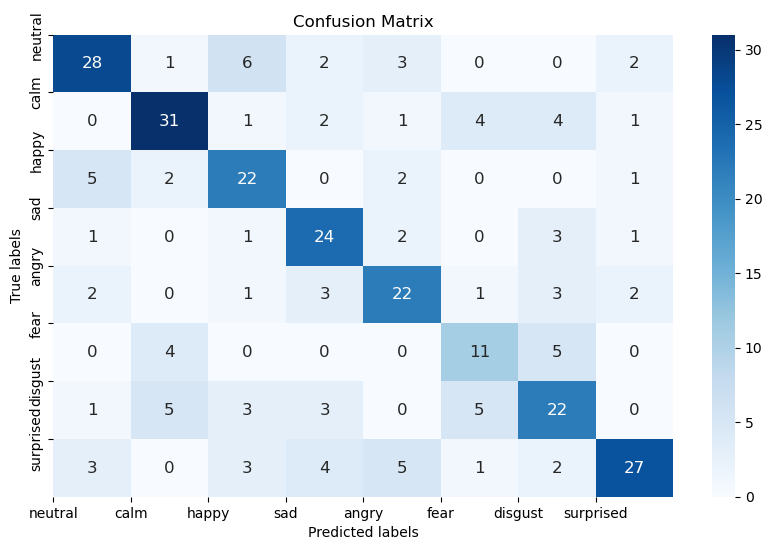

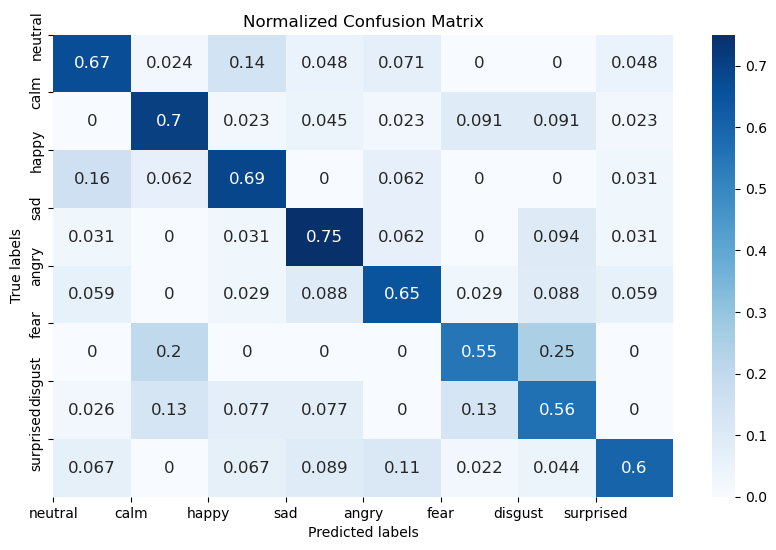

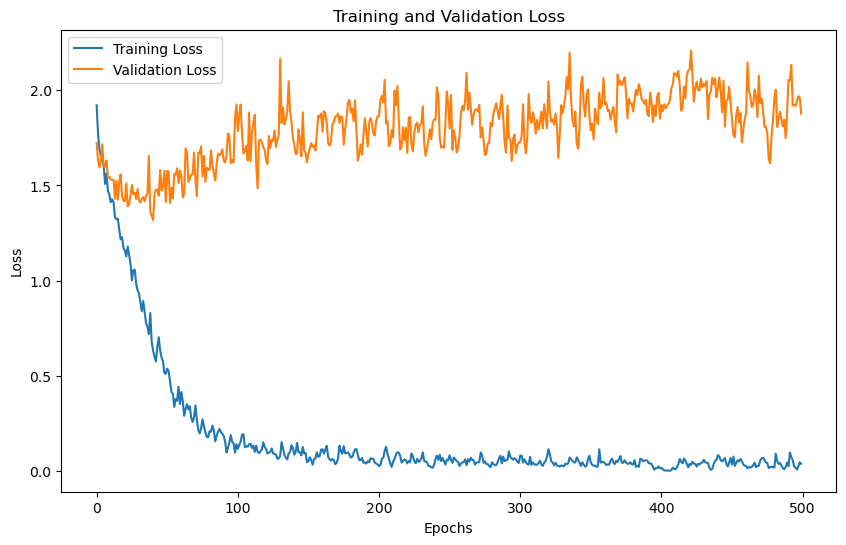

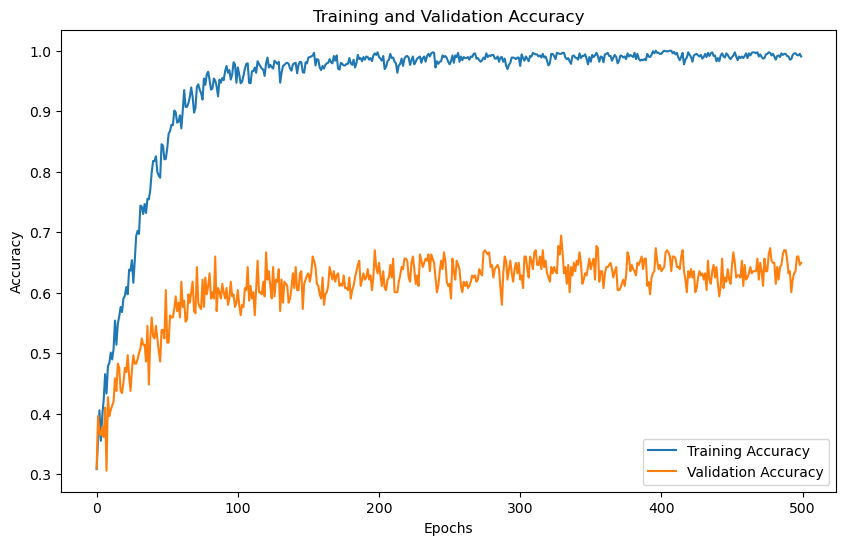

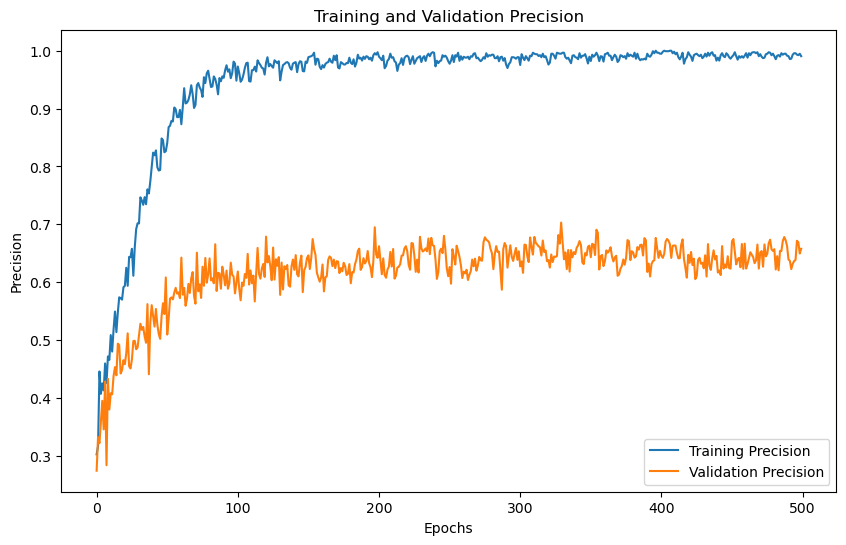

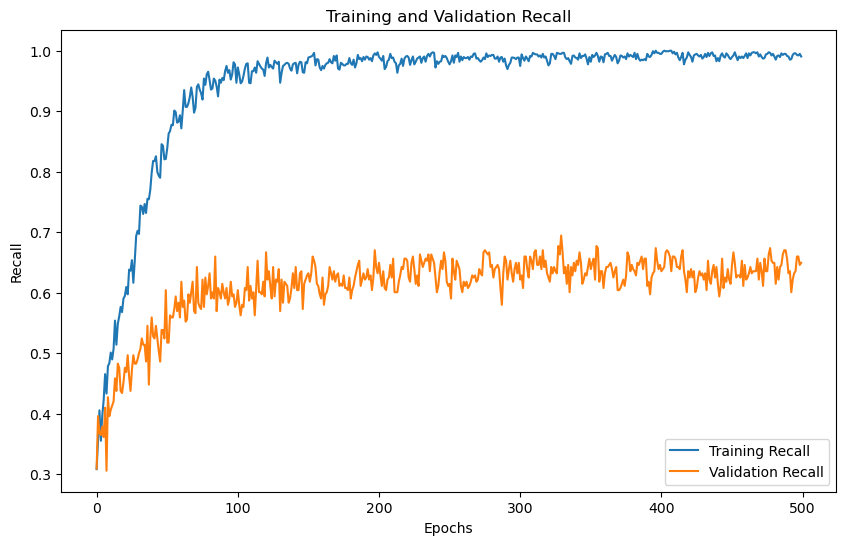

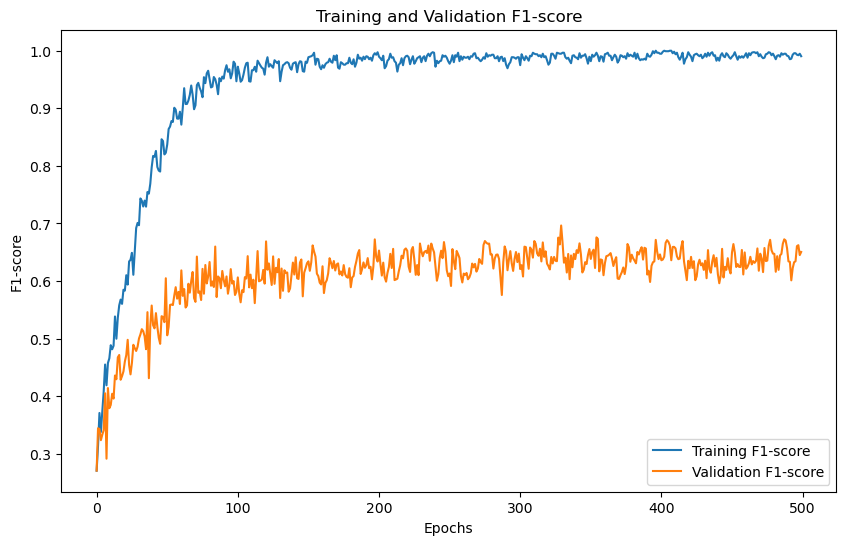

'Model Training and Evaluation Successfully completed'

In [24]:
train_model()

# N_MFCC 32

# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 ravdess
Enter N_MFCC:  32
No. of classes 8
Training with N_MFCC: 32
Input size : 1
Hidden Size : 256
Model Name: Resnet18_LSTM_Model

X Shape : (1440, 1, 32)
Y Shape : (1440, 8)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.9072, Training Accuracy: 0.3151, Training Precision:0.3179,Training Recall:0.3151,Training F1-Score:0.2623
Validation Loss: 1.7664, Validation Accuracy: 0.3021, Validation Precision:0.2698,Validation Recall:0.3021,Validation F1-Score:0.2231
Epoch [2/500],
Training Loss: 1.7074, Training Accuracy: 0.3863, Training Precision:0.4026,Training Recall:0.3863,Training F1-Score:0.3472
Validation Loss: 1.6631, Validation Accuracy: 0.3507, Validation Precision:0.3780,Validation Recall:0.3507,Validation F1-Score:0.3154
Epoch [3/500],
Training Loss: 1.6278, Training Accuracy: 0.4253, Training Precision:0.4120,Training Recall:0.4253,Training F1-Score:0.4119
Validation Loss: 1.6028, Validation Accuracy: 0.3889, Validatio

Epoch [31/500],
Training Loss: 0.8705, Training Accuracy: 0.7378, Training Precision:0.7401,Training Recall:0.7378,Training F1-Score:0.7355
Validation Loss: 1.3054, Validation Accuracy: 0.5382, Validation Precision:0.5382,Validation Recall:0.5382,Validation F1-Score:0.5273
Epoch [32/500],
Training Loss: 0.8178, Training Accuracy: 0.7300, Training Precision:0.7310,Training Recall:0.7300,Training F1-Score:0.7294
Validation Loss: 1.2358, Validation Accuracy: 0.5521, Validation Precision:0.5594,Validation Recall:0.5521,Validation F1-Score:0.5512
Epoch [33/500],
Training Loss: 0.7705, Training Accuracy: 0.7474, Training Precision:0.7492,Training Recall:0.7474,Training F1-Score:0.7458
Validation Loss: 1.2673, Validation Accuracy: 0.5521, Validation Precision:0.5613,Validation Recall:0.5521,Validation F1-Score:0.5471
Epoch [34/500],
Training Loss: 0.7195, Training Accuracy: 0.7552, Training Precision:0.7617,Training Recall:0.7552,Training F1-Score:0.7546
Validation Loss: 1.3549, Validation Ac

Epoch [61/500],
Training Loss: 0.3761, Training Accuracy: 0.9132, Training Precision:0.9142,Training Recall:0.9132,Training F1-Score:0.9130
Validation Loss: 1.4996, Validation Accuracy: 0.5590, Validation Precision:0.5748,Validation Recall:0.5590,Validation F1-Score:0.5576
Epoch [62/500],
Training Loss: 0.2933, Training Accuracy: 0.9219, Training Precision:0.9253,Training Recall:0.9219,Training F1-Score:0.9223
Validation Loss: 1.3599, Validation Accuracy: 0.6181, Validation Precision:0.6434,Validation Recall:0.6181,Validation F1-Score:0.6240
Epoch [63/500],
Training Loss: 0.2689, Training Accuracy: 0.9262, Training Precision:0.9289,Training Recall:0.9262,Training F1-Score:0.9267
Validation Loss: 1.4034, Validation Accuracy: 0.6111, Validation Precision:0.6404,Validation Recall:0.6111,Validation F1-Score:0.6149
Epoch [64/500],
Training Loss: 0.3207, Training Accuracy: 0.9297, Training Precision:0.9306,Training Recall:0.9297,Training F1-Score:0.9297
Validation Loss: 1.5710, Validation Ac

Epoch [91/500],
Training Loss: 0.1604, Training Accuracy: 0.9601, Training Precision:0.9602,Training Recall:0.9601,Training F1-Score:0.9601
Validation Loss: 1.6264, Validation Accuracy: 0.6285, Validation Precision:0.6407,Validation Recall:0.6285,Validation F1-Score:0.6297
Epoch [92/500],
Training Loss: 0.1436, Training Accuracy: 0.9523, Training Precision:0.9532,Training Recall:0.9523,Training F1-Score:0.9522
Validation Loss: 1.5792, Validation Accuracy: 0.6146, Validation Precision:0.6290,Validation Recall:0.6146,Validation F1-Score:0.6158
Epoch [93/500],
Training Loss: 0.2298, Training Accuracy: 0.9479, Training Precision:0.9482,Training Recall:0.9479,Training F1-Score:0.9480
Validation Loss: 1.5448, Validation Accuracy: 0.6250, Validation Precision:0.6464,Validation Recall:0.6250,Validation F1-Score:0.6268
Epoch [94/500],
Training Loss: 0.1764, Training Accuracy: 0.9531, Training Precision:0.9537,Training Recall:0.9531,Training F1-Score:0.9532
Validation Loss: 1.6044, Validation Ac

Epoch [121/500],
Training Loss: 0.0900, Training Accuracy: 0.9688, Training Precision:0.9692,Training Recall:0.9688,Training F1-Score:0.9687
Validation Loss: 1.6847, Validation Accuracy: 0.6458, Validation Precision:0.6574,Validation Recall:0.6458,Validation F1-Score:0.6459
Epoch [122/500],
Training Loss: 0.1074, Training Accuracy: 0.9783, Training Precision:0.9786,Training Recall:0.9783,Training F1-Score:0.9783
Validation Loss: 1.7592, Validation Accuracy: 0.6458, Validation Precision:0.6445,Validation Recall:0.6458,Validation F1-Score:0.6406
Epoch [123/500],
Training Loss: 0.1038, Training Accuracy: 0.9818, Training Precision:0.9820,Training Recall:0.9818,Training F1-Score:0.9817
Validation Loss: 1.4602, Validation Accuracy: 0.6667, Validation Precision:0.6673,Validation Recall:0.6667,Validation F1-Score:0.6629
Epoch [124/500],
Training Loss: 0.0637, Training Accuracy: 0.9826, Training Precision:0.9829,Training Recall:0.9826,Training F1-Score:0.9827
Validation Loss: 1.5640, Validatio

...

Epoch [361/500],
Training Loss: 0.0393, Training Accuracy: 0.9878, Training Precision:0.9881,Training Recall:0.9878,Training F1-Score:0.9879
Validation Loss: 1.6195, Validation Accuracy: 0.6632, Validation Precision:0.6849,Validation Recall:0.6632,Validation F1-Score:0.6675
Epoch [362/500],
Training Loss: 0.0300, Training Accuracy: 0.9913, Training Precision:0.9914,Training Recall:0.9913,Training F1-Score:0.9913
Validation Loss: 1.6834, Validation Accuracy: 0.6562, Validation Precision:0.6697,Validation Recall:0.6562,Validation F1-Score:0.6560
Epoch [363/500],
Training Loss: 0.0283, Training Accuracy: 0.9939, Training Precision:0.9940,Training Recall:0.9939,Training F1-Score:0.9939
Validation Loss: 1.7497, Validation Accuracy: 0.6597, Validation Precision:0.6689,Validation Recall:0.6597,Validation F1-Score:0.6567
Epoch [364/500],
Training Loss: 0.0521, Training Accuracy: 0.9948, Training Precision:0.9948,Training Recall:0.9948,Training F1-Score:0.9948
Validation Loss: 1.6712, Validatio

Epoch [391/500],
Training Loss: 0.0598, Training Accuracy: 0.9878, Training Precision:0.9879,Training Recall:0.9878,Training F1-Score:0.9878
Validation Loss: 1.7189, Validation Accuracy: 0.6701, Validation Precision:0.6720,Validation Recall:0.6701,Validation F1-Score:0.6697
Epoch [392/500],
Training Loss: 0.0371, Training Accuracy: 0.9913, Training Precision:0.9914,Training Recall:0.9913,Training F1-Score:0.9913
Validation Loss: 1.7639, Validation Accuracy: 0.6910, Validation Precision:0.6957,Validation Recall:0.6910,Validation F1-Score:0.6920
Epoch [393/500],
Training Loss: 0.0154, Training Accuracy: 0.9957, Training Precision:0.9957,Training Recall:0.9957,Training F1-Score:0.9957
Validation Loss: 1.8363, Validation Accuracy: 0.6701, Validation Precision:0.6737,Validation Recall:0.6701,Validation F1-Score:0.6666
Epoch [394/500],
Training Loss: 0.0136, Training Accuracy: 0.9974, Training Precision:0.9974,Training Recall:0.9974,Training F1-Score:0.9974
Validation Loss: 1.8563, Validatio

Epoch [421/500],
Training Loss: 0.0284, Training Accuracy: 0.9878, Training Precision:0.9880,Training Recall:0.9878,Training F1-Score:0.9879
Validation Loss: 1.6476, Validation Accuracy: 0.6840, Validation Precision:0.6970,Validation Recall:0.6840,Validation F1-Score:0.6834
Epoch [422/500],
Training Loss: 0.0546, Training Accuracy: 0.9774, Training Precision:0.9788,Training Recall:0.9774,Training F1-Score:0.9776
Validation Loss: 1.6983, Validation Accuracy: 0.6840, Validation Precision:0.6940,Validation Recall:0.6840,Validation F1-Score:0.6834
Epoch [423/500],
Training Loss: 0.0992, Training Accuracy: 0.9844, Training Precision:0.9846,Training Recall:0.9844,Training F1-Score:0.9844
Validation Loss: 1.7397, Validation Accuracy: 0.6354, Validation Precision:0.6420,Validation Recall:0.6354,Validation F1-Score:0.6362
Epoch [424/500],
Training Loss: 0.0787, Training Accuracy: 0.9844, Training Precision:0.9845,Training Recall:0.9844,Training F1-Score:0.9844
Validation Loss: 1.7881, Validatio

Epoch [451/500],
Training Loss: 0.0146, Training Accuracy: 0.9974, Training Precision:0.9974,Training Recall:0.9974,Training F1-Score:0.9974
Validation Loss: 1.7293, Validation Accuracy: 0.7014, Validation Precision:0.7113,Validation Recall:0.7014,Validation F1-Score:0.7002
Epoch [452/500],
Training Loss: 0.0212, Training Accuracy: 0.9991, Training Precision:0.9991,Training Recall:0.9991,Training F1-Score:0.9991
Validation Loss: 1.6897, Validation Accuracy: 0.7049, Validation Precision:0.7167,Validation Recall:0.7049,Validation F1-Score:0.7017
Epoch [453/500],
Training Loss: 0.0086, Training Accuracy: 0.9948, Training Precision:0.9949,Training Recall:0.9948,Training F1-Score:0.9948
Validation Loss: 1.7323, Validation Accuracy: 0.6875, Validation Precision:0.6958,Validation Recall:0.6875,Validation F1-Score:0.6854
Epoch [454/500],
Training Loss: 0.0182, Training Accuracy: 0.9905, Training Precision:0.9907,Training Recall:0.9905,Training F1-Score:0.9904
Validation Loss: 1.8343, Validatio

Epoch [481/500],
Training Loss: 0.0092, Training Accuracy: 0.9948, Training Precision:0.9948,Training Recall:0.9948,Training F1-Score:0.9948
Validation Loss: 1.9574, Validation Accuracy: 0.6632, Validation Precision:0.6698,Validation Recall:0.6632,Validation F1-Score:0.6650
Epoch [482/500],
Training Loss: 0.0246, Training Accuracy: 0.9957, Training Precision:0.9957,Training Recall:0.9957,Training F1-Score:0.9957
Validation Loss: 1.8761, Validation Accuracy: 0.6701, Validation Precision:0.6745,Validation Recall:0.6701,Validation F1-Score:0.6715
Epoch [483/500],
Training Loss: 0.0150, Training Accuracy: 0.9939, Training Precision:0.9941,Training Recall:0.9939,Training F1-Score:0.9939
Validation Loss: 1.8808, Validation Accuracy: 0.6528, Validation Precision:0.6580,Validation Recall:0.6528,Validation F1-Score:0.6535
Epoch [484/500],
Training Loss: 0.0269, Training Accuracy: 0.9957, Training Precision:0.9958,Training Recall:0.9957,Training F1-Score:0.9957
Validation Loss: 1.9235, Validatio

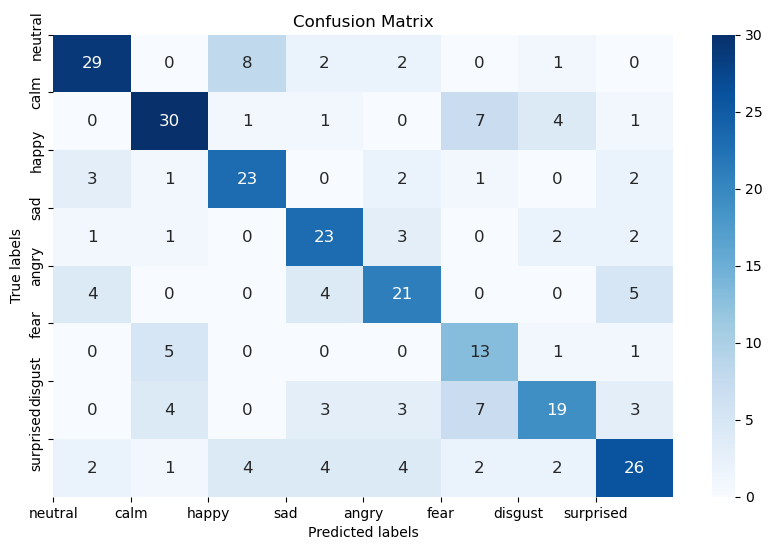

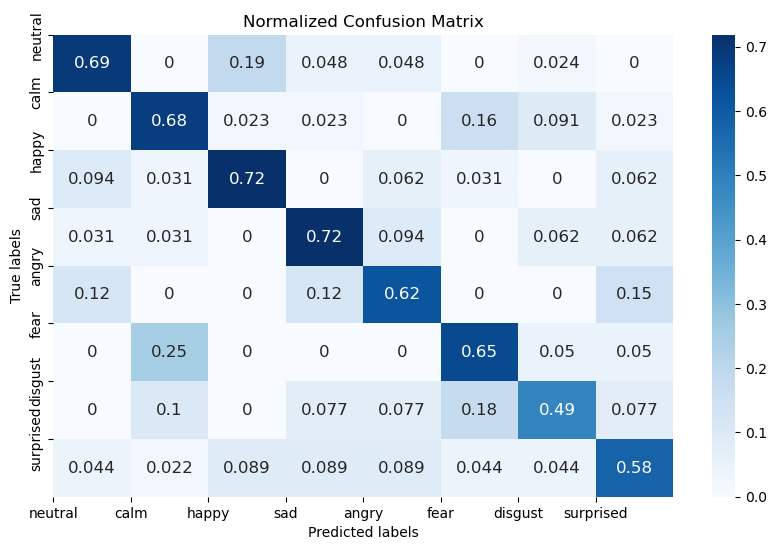

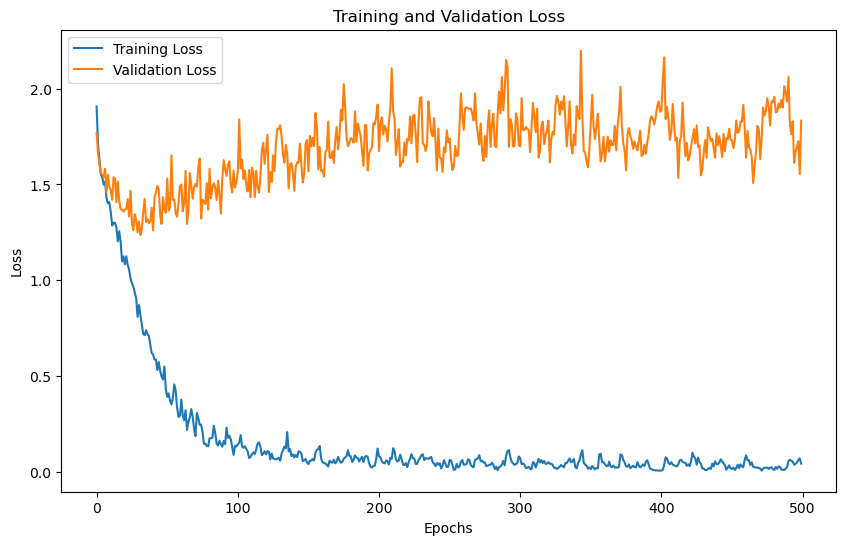

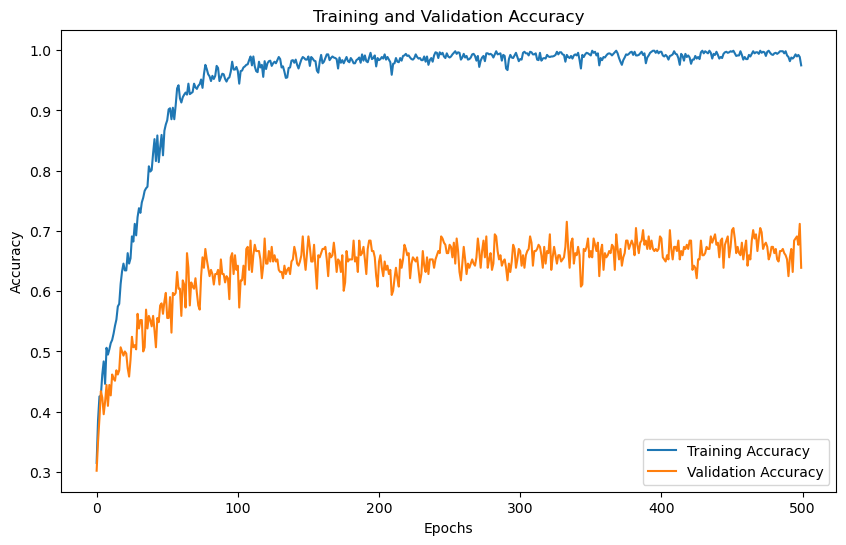

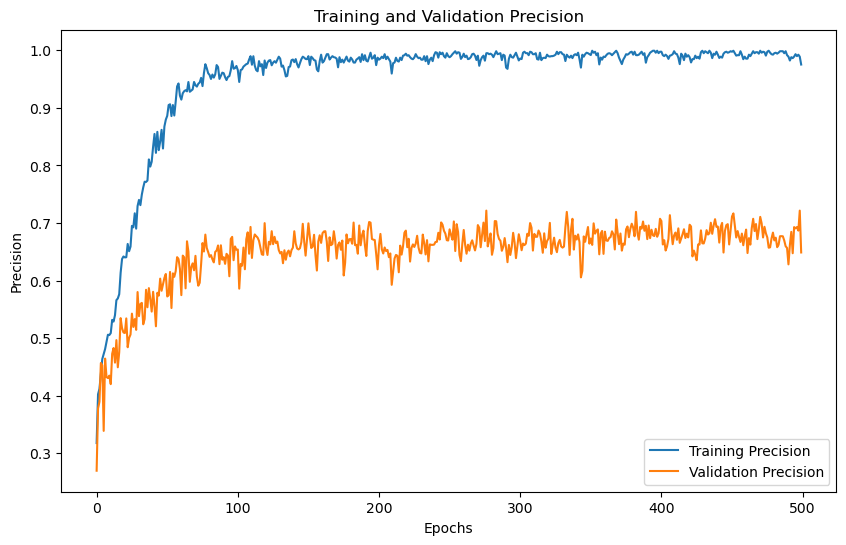

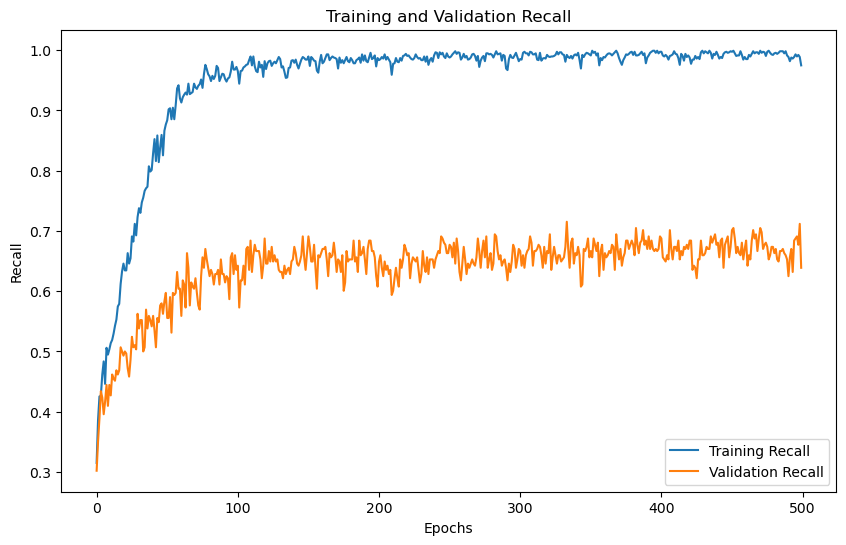

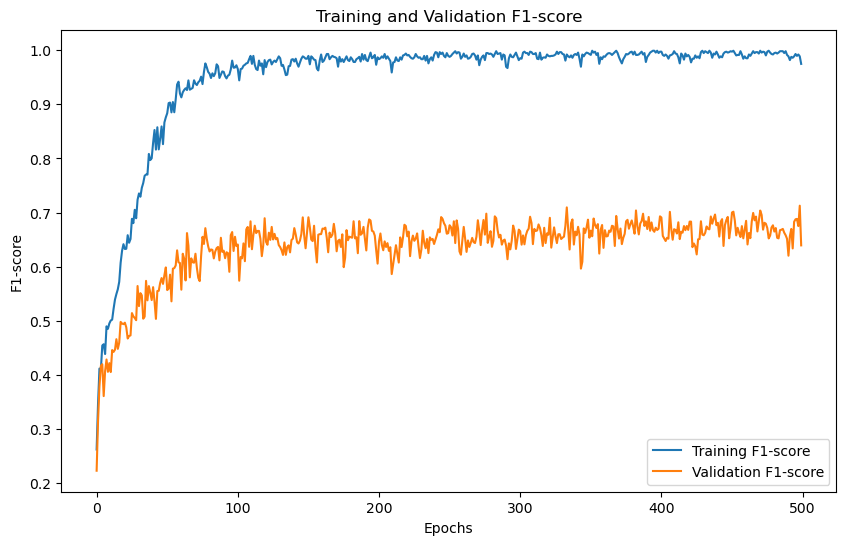

'Model Training and Evaluation Successfully completed'

In [31]:
train_model()

# N_MFCC 40

# 500 epochs

In [ ]:
train_model()

# CREMA

# N_MFCC 16

# 500 epochs

In [21]:
train_model()

Enter dataset name:
tess, savee, crema, ravdess
 crema
Enter N_MFCC:  16
No. of classes 6
Training with N_MFCC: 16
Input size : 1
Hidden Size : 256
Model Name: Resnet18_LSTM_Model

X Shape : (7442, 1, 16)
Y Shape : (7442, 6)

Enter no. of epochs 500


ValueError: Expected more than 1 value per channel when training, got input size torch.Size([1, 256, 1, 1])

# N_MFCC 24

# 500 epochs

In [28]:
train_model()

Enter dataset name:
tess, savee, crema, ravdess
 crema
Enter N_MFCC:  24
No. of classes 6
Training with N_MFCC: 24
Input size : 1
Hidden Size : 256
Model Name: Resnet18_LSTM_Model

X Shape : (7442, 1, 24)
Y Shape : (7442, 6)

Enter no. of epochs 500


ValueError: Expected more than 1 value per channel when training, got input size torch.Size([1, 512, 1, 1])

# N_MFCC 32

# 500 epochs

In [30]:
train_model()

Enter dataset name:
tess, savee, crema, ravdess
 crema
Enter N_MFCC:  32
No. of classes 6
Training with N_MFCC: 32
Input size : 1
Hidden Size : 256
Model Name: Resnet18_LSTM_Model

X Shape : (7442, 1, 32)
Y Shape : (7442, 6)

Enter no. of epochs 500


ValueError: Expected more than 1 value per channel when training, got input size torch.Size([1, 512, 1, 1])

# N_MFCC 40

# 500 epochs

In [ ]:
train_model()

# TESS

# N_MFCC 16

# 500 epoch

Enter dataset name:
tess, savee, crema, ravdess
 tess
Enter N_MFCC:  16
No. of classes 7
Training with N_MFCC: 16
Input size : 1
Hidden Size : 256
Model Name: Resnet18_LSTM_Model

X Shape : (2800, 1, 16)
Y Shape : (2800, 7)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.2555, Training Accuracy: 0.7036, Training Precision:0.7064,Training Recall:0.7036,Training F1-Score:0.6985
Validation Loss: 0.7519, Validation Accuracy: 0.7482, Validation Precision:0.7561,Validation Recall:0.7482,Validation F1-Score:0.7443
Epoch [2/500],
Training Loss: 0.7399, Training Accuracy: 0.7250, Training Precision:0.7287,Training Recall:0.7250,Training F1-Score:0.7188
Validation Loss: 0.7139, Validation Accuracy: 0.7571, Validation Precision:0.7657,Validation Recall:0.7571,Validation F1-Score:0.7534
Epoch [3/500],
Training Loss: 0.6406, Training Accuracy: 0.7964, Training Precision:0.8131,Training Recall:0.7964,Training F1-Score:0.7966
Validation Loss: 0.5593, Validation Accuracy: 0.8268, Validation P

Epoch [31/500],
Training Loss: 0.1431, Training Accuracy: 0.9496, Training Precision:0.9507,Training Recall:0.9496,Training F1-Score:0.9493
Validation Loss: 0.1826, Validation Accuracy: 0.9393, Validation Precision:0.9444,Validation Recall:0.9393,Validation F1-Score:0.9384
Epoch [32/500],
Training Loss: 0.1704, Training Accuracy: 0.9482, Training Precision:0.9501,Training Recall:0.9482,Training F1-Score:0.9480
Validation Loss: 0.2073, Validation Accuracy: 0.9232, Validation Precision:0.9252,Validation Recall:0.9232,Validation F1-Score:0.9230
Epoch [33/500],
Training Loss: 0.1302, Training Accuracy: 0.9679, Training Precision:0.9680,Training Recall:0.9679,Training F1-Score:0.9678
Validation Loss: 0.1467, Validation Accuracy: 0.9518, Validation Precision:0.9527,Validation Recall:0.9518,Validation F1-Score:0.9517
Epoch [34/500],
Training Loss: 0.1219, Training Accuracy: 0.9504, Training Precision:0.9530,Training Recall:0.9504,Training F1-Score:0.9507
Validation Loss: 0.2037, Validation Ac

Epoch [61/500],
Training Loss: 0.0955, Training Accuracy: 0.9723, Training Precision:0.9727,Training Recall:0.9723,Training F1-Score:0.9723
Validation Loss: 0.1309, Validation Accuracy: 0.9571, Validation Precision:0.9579,Validation Recall:0.9571,Validation F1-Score:0.9572
Epoch [62/500],
Training Loss: 0.0713, Training Accuracy: 0.9821, Training Precision:0.9824,Training Recall:0.9821,Training F1-Score:0.9821
Validation Loss: 0.1268, Validation Accuracy: 0.9554, Validation Precision:0.9563,Validation Recall:0.9554,Validation F1-Score:0.9555
Epoch [63/500],
Training Loss: 0.0965, Training Accuracy: 0.9848, Training Precision:0.9850,Training Recall:0.9848,Training F1-Score:0.9848
Validation Loss: 0.1153, Validation Accuracy: 0.9589, Validation Precision:0.9597,Validation Recall:0.9589,Validation F1-Score:0.9587
Epoch [64/500],
Training Loss: 0.0771, Training Accuracy: 0.9714, Training Precision:0.9716,Training Recall:0.9714,Training F1-Score:0.9714
Validation Loss: 0.1658, Validation Ac

Epoch [91/500],
Training Loss: 0.0537, Training Accuracy: 0.9844, Training Precision:0.9846,Training Recall:0.9844,Training F1-Score:0.9844
Validation Loss: 0.1194, Validation Accuracy: 0.9607, Validation Precision:0.9616,Validation Recall:0.9607,Validation F1-Score:0.9607
Epoch [92/500],
Training Loss: 0.0439, Training Accuracy: 0.9911, Training Precision:0.9913,Training Recall:0.9911,Training F1-Score:0.9911
Validation Loss: 0.1304, Validation Accuracy: 0.9643, Validation Precision:0.9646,Validation Recall:0.9643,Validation F1-Score:0.9643
Epoch [93/500],
Training Loss: 0.0265, Training Accuracy: 0.9875, Training Precision:0.9877,Training Recall:0.9875,Training F1-Score:0.9875
Validation Loss: 0.1659, Validation Accuracy: 0.9554, Validation Precision:0.9559,Validation Recall:0.9554,Validation F1-Score:0.9554
Epoch [94/500],
Training Loss: 0.0549, Training Accuracy: 0.9857, Training Precision:0.9858,Training Recall:0.9857,Training F1-Score:0.9857
Validation Loss: 0.1283, Validation Ac

Epoch [121/500],
Training Loss: 0.0747, Training Accuracy: 0.9871, Training Precision:0.9872,Training Recall:0.9871,Training F1-Score:0.9871
Validation Loss: 0.1572, Validation Accuracy: 0.9464, Validation Precision:0.9473,Validation Recall:0.9464,Validation F1-Score:0.9464
Epoch [122/500],
Training Loss: 0.0833, Training Accuracy: 0.9839, Training Precision:0.9841,Training Recall:0.9839,Training F1-Score:0.9839
Validation Loss: 0.1213, Validation Accuracy: 0.9661, Validation Precision:0.9663,Validation Recall:0.9661,Validation F1-Score:0.9660
Epoch [123/500],
Training Loss: 0.0604, Training Accuracy: 0.9866, Training Precision:0.9867,Training Recall:0.9866,Training F1-Score:0.9866
Validation Loss: 0.1463, Validation Accuracy: 0.9661, Validation Precision:0.9666,Validation Recall:0.9661,Validation F1-Score:0.9661
Epoch [124/500],
Training Loss: 0.0647, Training Accuracy: 0.9915, Training Precision:0.9915,Training Recall:0.9915,Training F1-Score:0.9915
Validation Loss: 0.1344, Validatio

...

Epoch [361/500],
Training Loss: 0.0202, Training Accuracy: 0.9929, Training Precision:0.9929,Training Recall:0.9929,Training F1-Score:0.9929
Validation Loss: 0.1998, Validation Accuracy: 0.9518, Validation Precision:0.9536,Validation Recall:0.9518,Validation F1-Score:0.9521
Epoch [362/500],
Training Loss: 0.0411, Training Accuracy: 0.9955, Training Precision:0.9956,Training Recall:0.9955,Training F1-Score:0.9955
Validation Loss: 0.1850, Validation Accuracy: 0.9518, Validation Precision:0.9526,Validation Recall:0.9518,Validation F1-Score:0.9518
Epoch [363/500],
Training Loss: 0.0160, Training Accuracy: 0.9973, Training Precision:0.9974,Training Recall:0.9973,Training F1-Score:0.9973
Validation Loss: 0.1476, Validation Accuracy: 0.9643, Validation Precision:0.9654,Validation Recall:0.9643,Validation F1-Score:0.9645
Epoch [364/500],
Training Loss: 0.0154, Training Accuracy: 0.9960, Training Precision:0.9960,Training Recall:0.9960,Training F1-Score:0.9960
Validation Loss: 0.1793, Validatio

Epoch [391/500],
Training Loss: 0.0146, Training Accuracy: 0.9982, Training Precision:0.9982,Training Recall:0.9982,Training F1-Score:0.9982
Validation Loss: 0.1678, Validation Accuracy: 0.9554, Validation Precision:0.9562,Validation Recall:0.9554,Validation F1-Score:0.9554
Epoch [392/500],
Training Loss: 0.0265, Training Accuracy: 0.9929, Training Precision:0.9930,Training Recall:0.9929,Training F1-Score:0.9928
Validation Loss: 0.2137, Validation Accuracy: 0.9464, Validation Precision:0.9468,Validation Recall:0.9464,Validation F1-Score:0.9464
Epoch [393/500],
Training Loss: 0.0177, Training Accuracy: 0.9969, Training Precision:0.9969,Training Recall:0.9969,Training F1-Score:0.9969
Validation Loss: 0.1766, Validation Accuracy: 0.9589, Validation Precision:0.9602,Validation Recall:0.9589,Validation F1-Score:0.9589
Epoch [394/500],
Training Loss: 0.0042, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 0.1537, Validatio

Epoch [421/500],
Training Loss: 0.0087, Training Accuracy: 0.9987, Training Precision:0.9987,Training Recall:0.9987,Training F1-Score:0.9987
Validation Loss: 0.1454, Validation Accuracy: 0.9625, Validation Precision:0.9631,Validation Recall:0.9625,Validation F1-Score:0.9626
Epoch [422/500],
Training Loss: 0.0222, Training Accuracy: 0.9857, Training Precision:0.9863,Training Recall:0.9857,Training F1-Score:0.9858
Validation Loss: 0.1895, Validation Accuracy: 0.9554, Validation Precision:0.9558,Validation Recall:0.9554,Validation F1-Score:0.9553
Epoch [423/500],
Training Loss: 0.0396, Training Accuracy: 0.9920, Training Precision:0.9920,Training Recall:0.9920,Training F1-Score:0.9920
Validation Loss: 0.2006, Validation Accuracy: 0.9518, Validation Precision:0.9523,Validation Recall:0.9518,Validation F1-Score:0.9516
Epoch [424/500],
Training Loss: 0.0327, Training Accuracy: 0.9884, Training Precision:0.9889,Training Recall:0.9884,Training F1-Score:0.9885
Validation Loss: 0.1938, Validatio

Epoch [451/500],
Training Loss: 0.0012, Training Accuracy: 0.9982, Training Precision:0.9982,Training Recall:0.9982,Training F1-Score:0.9982
Validation Loss: 0.1703, Validation Accuracy: 0.9589, Validation Precision:0.9595,Validation Recall:0.9589,Validation F1-Score:0.9589
Epoch [452/500],
Training Loss: 0.0016, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.1550, Validation Accuracy: 0.9625, Validation Precision:0.9629,Validation Recall:0.9625,Validation F1-Score:0.9625
Epoch [453/500],
Training Loss: 0.0005, Training Accuracy: 0.9987, Training Precision:0.9987,Training Recall:0.9987,Training F1-Score:0.9987
Validation Loss: 0.1398, Validation Accuracy: 0.9643, Validation Precision:0.9650,Validation Recall:0.9643,Validation F1-Score:0.9643
Epoch [454/500],
Training Loss: 0.0018, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.1347, Validatio

Epoch [481/500],
Training Loss: 0.0006, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.1726, Validation Accuracy: 0.9607, Validation Precision:0.9614,Validation Recall:0.9607,Validation F1-Score:0.9607
Epoch [482/500],
Training Loss: 0.0131, Training Accuracy: 0.9969, Training Precision:0.9969,Training Recall:0.9969,Training F1-Score:0.9969
Validation Loss: 0.1824, Validation Accuracy: 0.9625, Validation Precision:0.9636,Validation Recall:0.9625,Validation F1-Score:0.9625
Epoch [483/500],
Training Loss: 0.0029, Training Accuracy: 0.9964, Training Precision:0.9965,Training Recall:0.9964,Training F1-Score:0.9964
Validation Loss: 0.2464, Validation Accuracy: 0.9500, Validation Precision:0.9516,Validation Recall:0.9500,Validation F1-Score:0.9501
Epoch [484/500],
Training Loss: 0.0053, Training Accuracy: 0.9960, Training Precision:0.9960,Training Recall:0.9960,Training F1-Score:0.9960
Validation Loss: 0.2447, Validatio

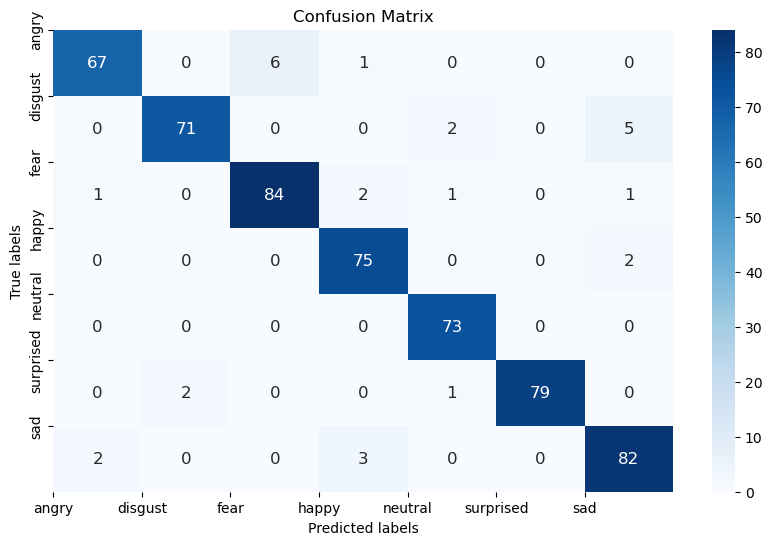

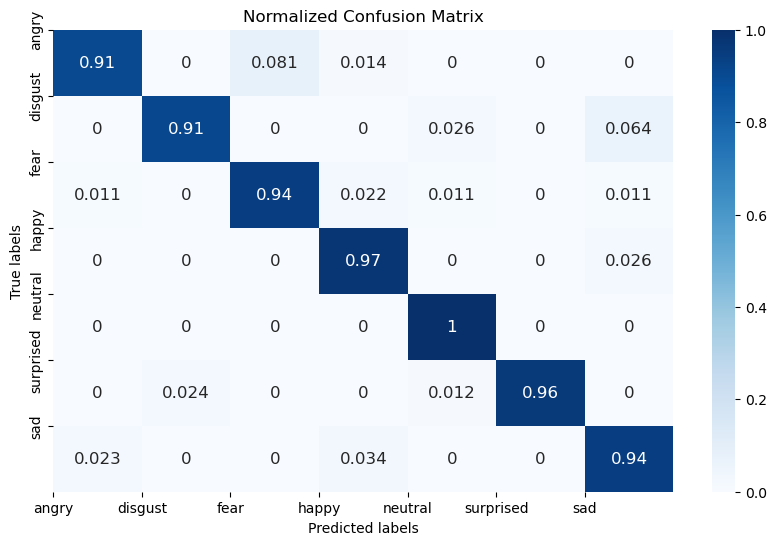

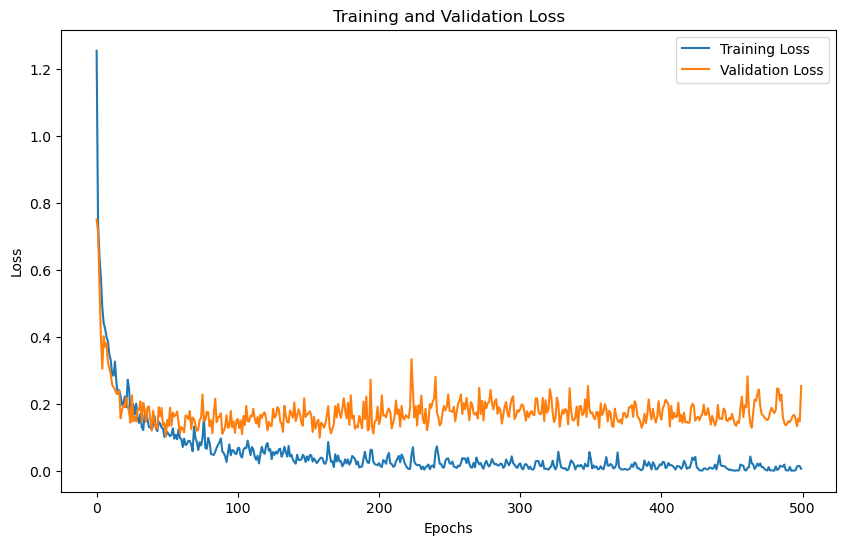

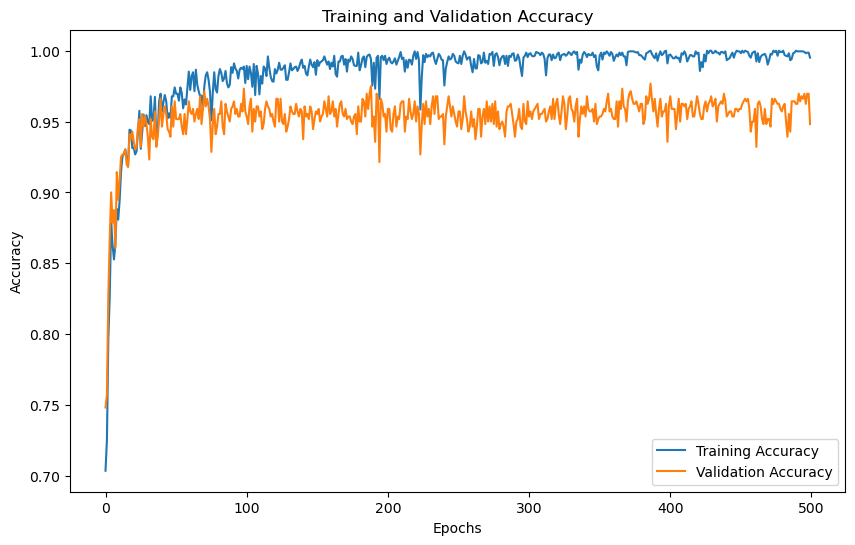

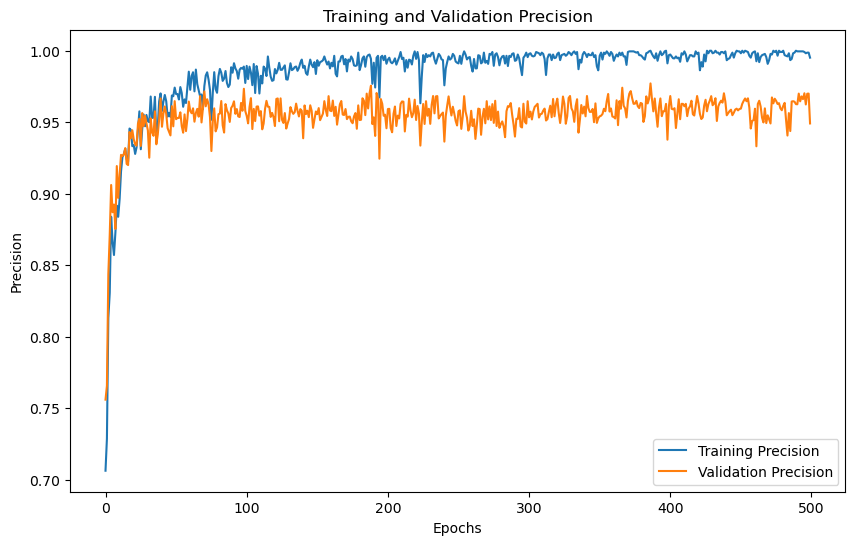

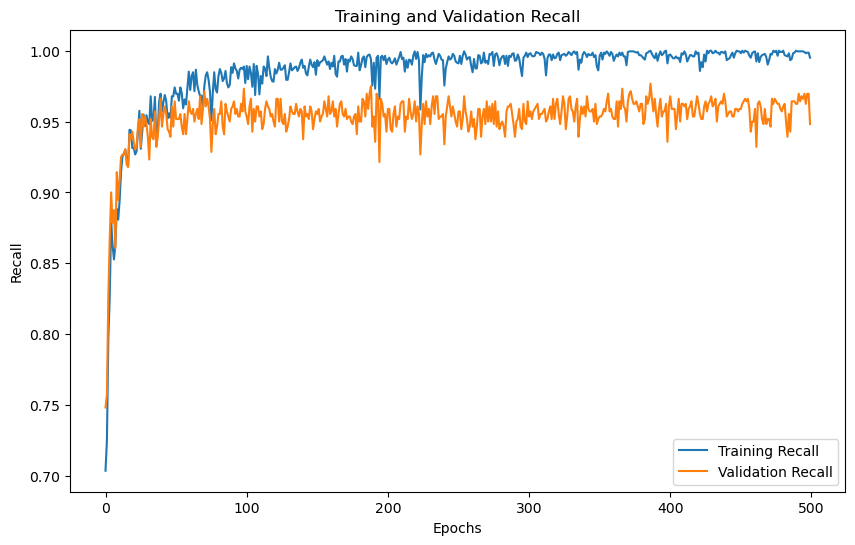

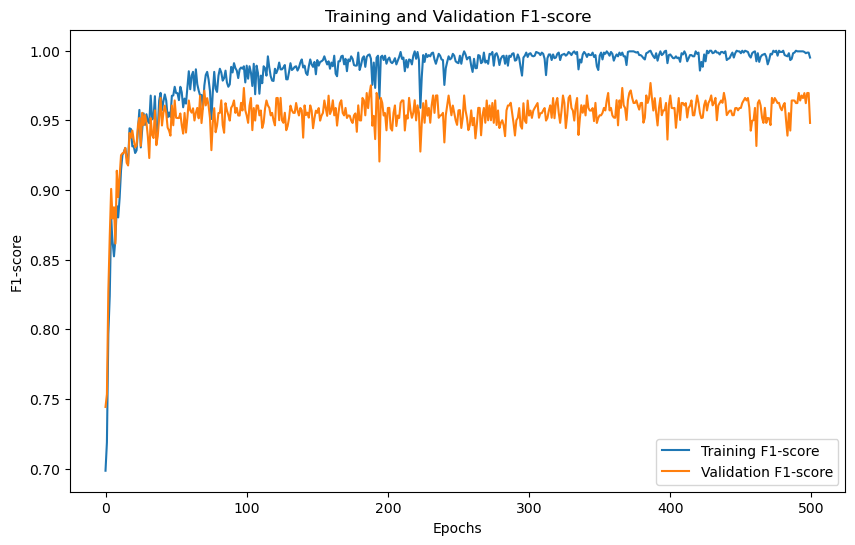

'Model Training and Evaluation Successfully completed'

In [26]:
train_model()

# N_MFCC 24

# 500 epoch

In [ ]:
train_model()

# N_MFCC 32

# 300 epoch

In [ ]:
train_model()

# N_MFCC 40

# 300 epochs

Enter dataset name:
tess, savee, crema, ravdess
 tess
Enter N_MFCC:  40
No. of classes 7
Training with N_MFCC: 40
Input size : 1
Hidden Size : 256
Model Name: Resnet18_LSTM_Model

X Shape : (2800, 1, 40)
Y Shape : (2800, 7)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 0.4803, Training Accuracy: 0.9563, Training Precision:0.9583,Training Recall:0.9563,Training F1-Score:0.9558
Validation Loss: 0.1425, Validation Accuracy: 0.9464, Validation Precision:0.9503,Validation Recall:0.9464,Validation F1-Score:0.9461
Epoch [2/500],
Training Loss: 0.1604, Training Accuracy: 0.9603, Training Precision:0.9615,Training Recall:0.9603,Training F1-Score:0.9602
Validation Loss: 0.0994, Validation Accuracy: 0.9696, Validation Precision:0.9700,Validation Recall:0.9696,Validation F1-Score:0.9696
Epoch [3/500],
Training Loss: 0.0984, Training Accuracy: 0.9790, Training Precision:0.9801,Training Recall:0.9790,Training F1-Score:0.9791
Validation Loss: 0.0444, Validation Accuracy: 0.9875, Validation P

Epoch [31/500],
Training Loss: 0.0109, Training Accuracy: 0.9987, Training Precision:0.9987,Training Recall:0.9987,Training F1-Score:0.9987
Validation Loss: 0.0159, Validation Accuracy: 0.9964, Validation Precision:0.9965,Validation Recall:0.9964,Validation F1-Score:0.9964
Epoch [32/500],
Training Loss: 0.0047, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0140, Validation Accuracy: 0.9964, Validation Precision:0.9965,Validation Recall:0.9964,Validation F1-Score:0.9964
Epoch [33/500],
Training Loss: 0.0011, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 0.0088, Validation Accuracy: 0.9964, Validation Precision:0.9965,Validation Recall:0.9964,Validation F1-Score:0.9964
Epoch [34/500],
Training Loss: 0.0062, Training Accuracy: 0.9982, Training Precision:0.9982,Training Recall:0.9982,Training F1-Score:0.9982
Validation Loss: 0.0240, Validation Ac

Epoch [61/500],
Training Loss: 0.0021, Training Accuracy: 0.9987, Training Precision:0.9987,Training Recall:0.9987,Training F1-Score:0.9987
Validation Loss: 0.0034, Validation Accuracy: 0.9982, Validation Precision:0.9982,Validation Recall:0.9982,Validation F1-Score:0.9982
Epoch [62/500],
Training Loss: 0.0066, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0119, Validation Accuracy: 0.9929, Validation Precision:0.9929,Validation Recall:0.9929,Validation F1-Score:0.9929
Epoch [63/500],
Training Loss: 0.0012, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0109, Validation Accuracy: 0.9964, Validation Precision:0.9965,Validation Recall:0.9964,Validation F1-Score:0.9964
Epoch [64/500],
Training Loss: 0.0028, Training Accuracy: 0.9964, Training Precision:0.9965,Training Recall:0.9964,Training F1-Score:0.9964
Validation Loss: 0.0222, Validation Ac

Epoch [91/500],
Training Loss: 0.0066, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0195, Validation Accuracy: 0.9929, Validation Precision:0.9929,Validation Recall:0.9929,Validation F1-Score:0.9929
Epoch [92/500],
Training Loss: 0.0050, Training Accuracy: 0.9991, Training Precision:0.9991,Training Recall:0.9991,Training F1-Score:0.9991
Validation Loss: 0.0198, Validation Accuracy: 0.9964, Validation Precision:0.9965,Validation Recall:0.9964,Validation F1-Score:0.9964
Epoch [93/500],
Training Loss: 0.0116, Training Accuracy: 0.9982, Training Precision:0.9982,Training Recall:0.9982,Training F1-Score:0.9982
Validation Loss: 0.0141, Validation Accuracy: 0.9964, Validation Precision:0.9965,Validation Recall:0.9964,Validation F1-Score:0.9964
Epoch [94/500],
Training Loss: 0.0112, Training Accuracy: 0.9991, Training Precision:0.9991,Training Recall:0.9991,Training F1-Score:0.9991
Validation Loss: 0.0200, Validation Ac

Epoch [121/500],
Training Loss: 0.0003, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 0.0095, Validation Accuracy: 0.9982, Validation Precision:0.9982,Validation Recall:0.9982,Validation F1-Score:0.9982
Epoch [122/500],
Training Loss: 0.0004, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0135, Validation Accuracy: 0.9982, Validation Precision:0.9982,Validation Recall:0.9982,Validation F1-Score:0.9982
Epoch [123/500],
Training Loss: 0.0002, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0149, Validation Accuracy: 0.9982, Validation Precision:0.9982,Validation Recall:0.9982,Validation F1-Score:0.9982
Epoch [124/500],
Training Loss: 0.0308, Training Accuracy: 0.9924, Training Precision:0.9925,Training Recall:0.9924,Training F1-Score:0.9924
Validation Loss: 0.0400, Validatio

...

Epoch [361/500],
Training Loss: 0.0005, Training Accuracy: 0.9987, Training Precision:0.9987,Training Recall:0.9987,Training F1-Score:0.9987
Validation Loss: 0.0250, Validation Accuracy: 0.9964, Validation Precision:0.9965,Validation Recall:0.9964,Validation F1-Score:0.9964
Epoch [362/500],
Training Loss: 0.0006, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 0.0276, Validation Accuracy: 0.9946, Validation Precision:0.9948,Validation Recall:0.9946,Validation F1-Score:0.9947
Epoch [363/500],
Training Loss: 0.0011, Training Accuracy: 0.9991, Training Precision:0.9991,Training Recall:0.9991,Training F1-Score:0.9991
Validation Loss: 0.0176, Validation Accuracy: 0.9964, Validation Precision:0.9965,Validation Recall:0.9964,Validation F1-Score:0.9964
Epoch [364/500],
Training Loss: 0.0185, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 0.0106, Validatio

Epoch [391/500],
Training Loss: 0.0006, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0188, Validation Accuracy: 0.9946, Validation Precision:0.9947,Validation Recall:0.9946,Validation F1-Score:0.9947
Epoch [392/500],
Training Loss: 0.0059, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0192, Validation Accuracy: 0.9964, Validation Precision:0.9965,Validation Recall:0.9964,Validation F1-Score:0.9964
Epoch [393/500],
Training Loss: 0.0013, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0190, Validation Accuracy: 0.9964, Validation Precision:0.9965,Validation Recall:0.9964,Validation F1-Score:0.9964
Epoch [394/500],
Training Loss: 0.0007, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0099, Validatio

Epoch [421/500],
Training Loss: 0.0001, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 0.0268, Validation Accuracy: 0.9964, Validation Precision:0.9965,Validation Recall:0.9964,Validation F1-Score:0.9964
Epoch [422/500],
Training Loss: 0.0002, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0251, Validation Accuracy: 0.9964, Validation Precision:0.9965,Validation Recall:0.9964,Validation F1-Score:0.9964
Epoch [423/500],
Training Loss: 0.0003, Training Accuracy: 0.9996, Training Precision:0.9996,Training Recall:0.9996,Training F1-Score:0.9996
Validation Loss: 0.0291, Validation Accuracy: 0.9964, Validation Precision:0.9965,Validation Recall:0.9964,Validation F1-Score:0.9964
Epoch [424/500],
Training Loss: 0.0005, Training Accuracy: 0.9987, Training Precision:0.9987,Training Recall:0.9987,Training F1-Score:0.9987
Validation Loss: 0.0297, Validatio

Epoch [451/500],
Training Loss: 0.0001, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0328, Validation Accuracy: 0.9946, Validation Precision:0.9948,Validation Recall:0.9946,Validation F1-Score:0.9946
Epoch [452/500],
Training Loss: 0.0001, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0345, Validation Accuracy: 0.9929, Validation Precision:0.9931,Validation Recall:0.9929,Validation F1-Score:0.9929
Epoch [453/500],
Training Loss: 0.0003, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0276, Validation Accuracy: 0.9946, Validation Precision:0.9948,Validation Recall:0.9946,Validation F1-Score:0.9946
Epoch [454/500],
Training Loss: 0.0002, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0243, Validatio

Epoch [481/500],
Training Loss: 0.0001, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0011, Validation Accuracy: 1.0000, Validation Precision:1.0000,Validation Recall:1.0000,Validation F1-Score:1.0000
Epoch [482/500],
Training Loss: 0.0002, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0141, Validation Accuracy: 0.9964, Validation Precision:0.9965,Validation Recall:0.9964,Validation F1-Score:0.9964
Epoch [483/500],
Training Loss: 0.0002, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0135, Validation Accuracy: 0.9964, Validation Precision:0.9965,Validation Recall:0.9964,Validation F1-Score:0.9964
Epoch [484/500],
Training Loss: 0.0001, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0189, Validatio

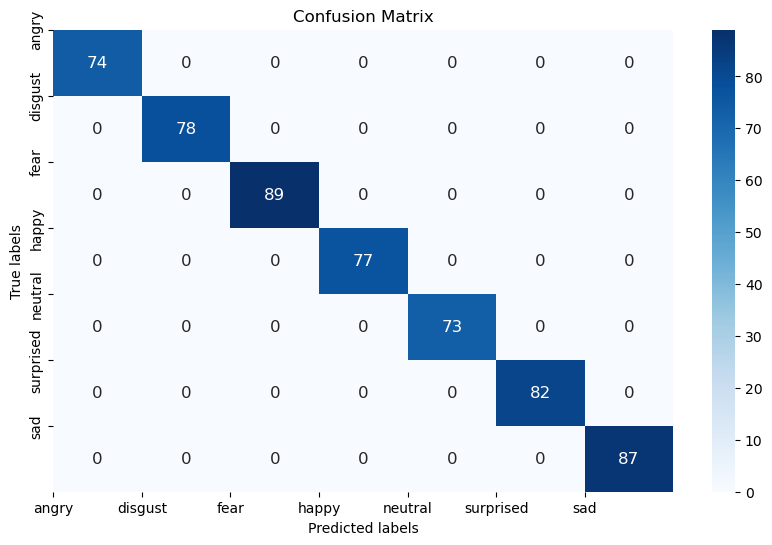

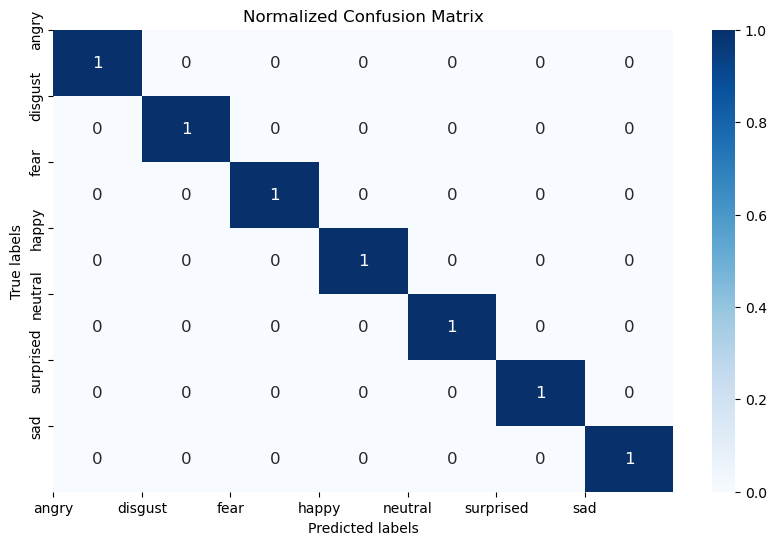

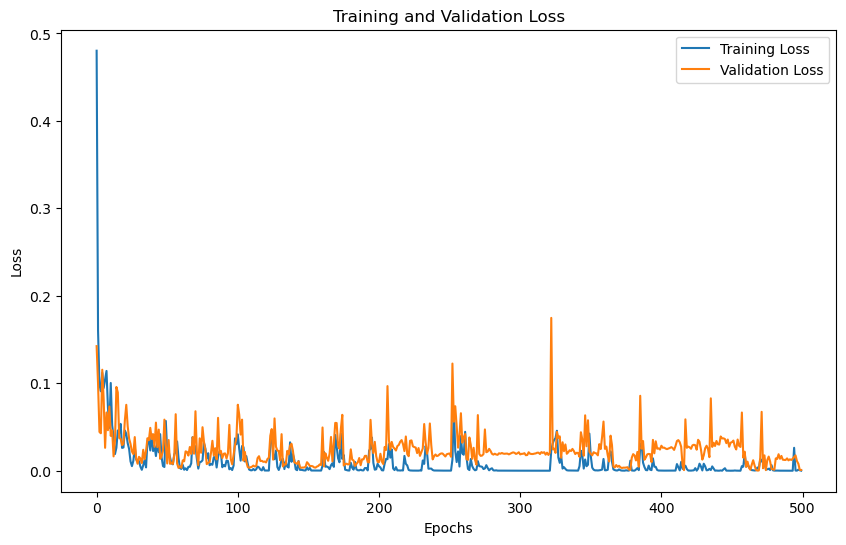

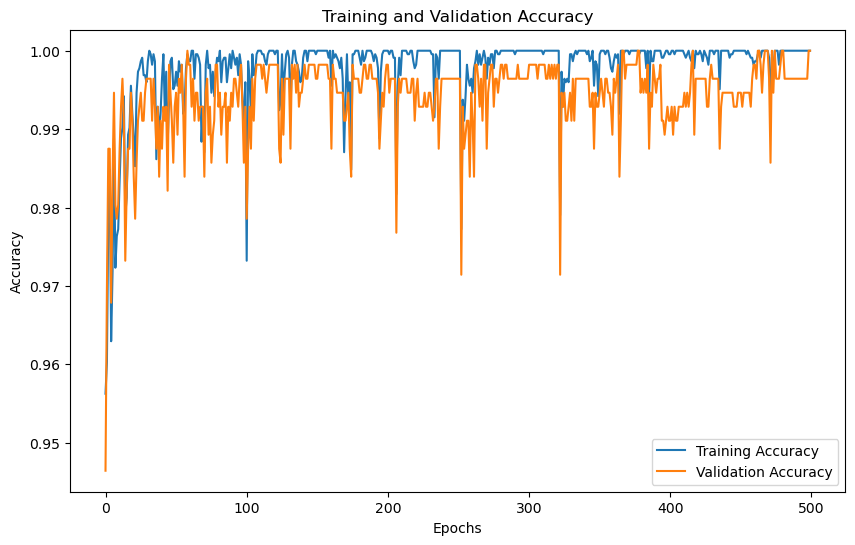

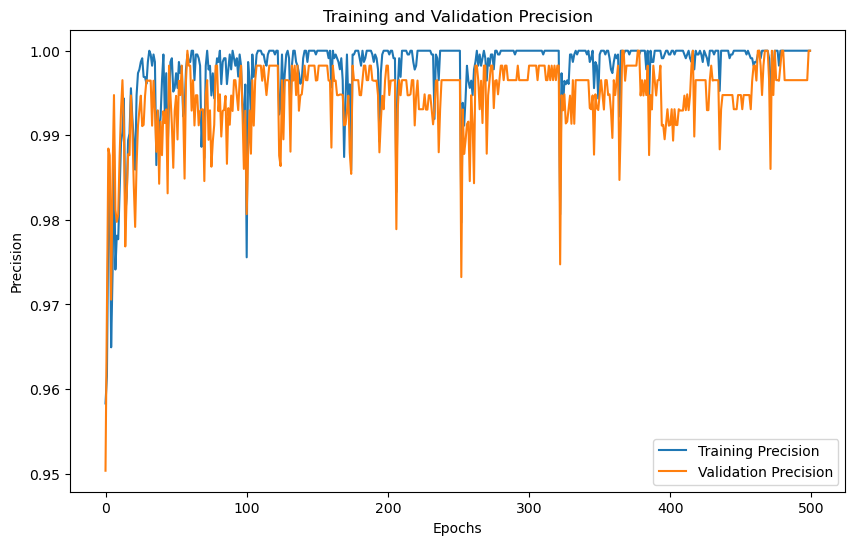

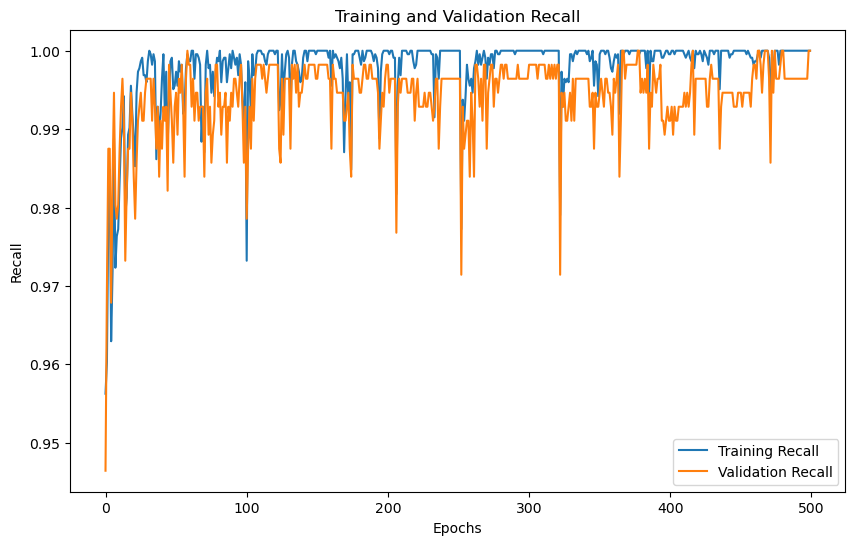

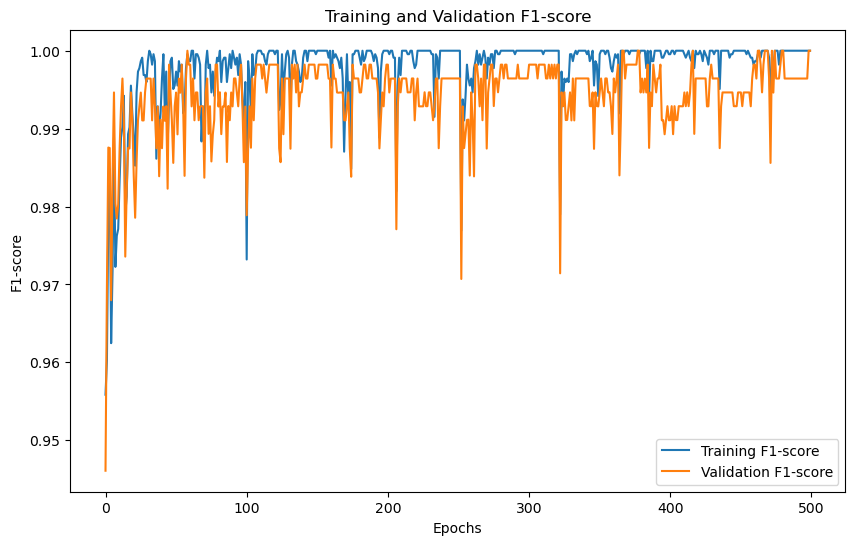

'Model Training and Evaluation Successfully completed'

In [23]:
train_model()